[Tomopy Documentation](https://tomopy.readthedocs.io/en/stable/)

In [ ]:

import os
import numpy as np
from skimage.io import imread, imsave
import matplotlib.pyplot as plt
from scipy.ndimage import rotate, shift
#import dxchange
import time
import tifffile

from skimage.registration import phase_cross_correlation
from skimage.transform import warp_polar
from numpy.fft import fftn, fft2, fftshift
import tifffile

import error as er

In [2]:
def load_sample_data(save_dir, sample_name, date):
    """
    Load back the cropped volume for one sample
    """
    volume_path = os.path.join(save_dir, f'{sample_name}_volume_{date}.npz')

    npz = np.load(volume_path)
    cropped = {
        'Mx': npz['Mx'], 'My': npz['My'], 'Mz': npz['Mz'],
        'magnitude': npz['magnitude'],
        'shape': tuple(npz['shape']),
    }
    spacing = tuple(npz['spacing'])
    z_offset = 0

    return cropped, spacing, z_offset

In [162]:
# import halfs 

sample_names = ['452', '270', '105', '665'] 
#dates = ['fsc_half1_TV_NOV26', 'fsc_half2_TV_NOV26', 'fsc_half1_TV_NOV26', 'fsc_half2_TV_NOV26'] 
dates = ['fsc_half1_noreg_NOV26', 'fsc_half2_noreg_NOV26'] 


sample_colors = ['limegreen', 'deeppink', 'cyan', 'gold']


sample = 0
sample_name = sample_names[sample]
half_1 = dates[0]
half_2 = dates[1]
sample_color = sample_colors[sample]

data_dir = f'C:/Users/emmab/Projects/Vector_Tomography/data_dir/{sample_name}/'

recon_volume_1, spacing, ___ = load_sample_data(data_dir, sample_name, half_1)
recon_volume_2, spacing, ___ = load_sample_data(data_dir, sample_name, half_2)
voxel_nm = spacing[0]



(5, 279, 279)
(5, 279, 279)
(5, 279, 279)
no window number of shells = 139
(5, 279, 279)
(5, 279, 279)
(5, 279, 279)
no window number of shells = 139


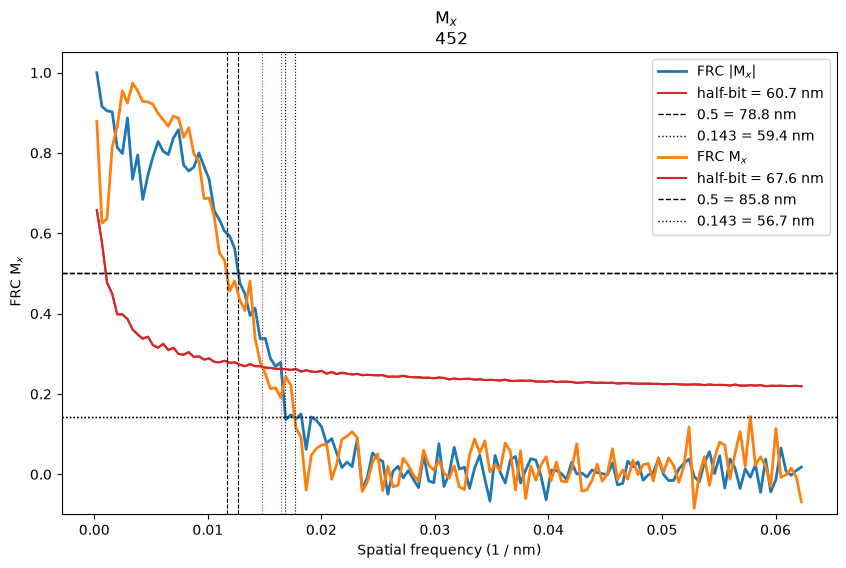

In [ ]:
## Run the FSC on mx 
plt.figure(figsize=(10, 6))  
mx_half1 = abs(recon_volume_1['Mx'])
print(mx_half1.shape)
mx_half2 = abs(recon_volume_2['Mx'])
print(mx_half2.shape)
title = f'|M$_x$|'

# freq, fsc, n, res = fourier_shell_correlation(mx_half1, mx_half2, voxel_nm, sample = sample_name, title = title)
freq, fsc, n, res = er.frc_stack_no_window(mx_half1, mx_half2, voxel_nm, sample = sample_name, title = title)


mx_half1 = (recon_volume_1['Mx'])
print(mx_half1.shape)
mx_half2 = (recon_volume_2['Mx'])
print(mx_half2.shape)
title = f'M$_x$'

# freq, fsc, n, res = fourier_shell_correlation(mx_half1, mx_half2, voxel_nm, sample = sample_name, title = title)

# freq, fsc, n, res = fourier_shell_correlation_bad(mx_half1, mx_half2, voxel_nm, n_shells = 143//2)


freq, fsc, n, res = er.frc_stack_no_window(mx_half1, mx_half2, voxel_nm, sample = sample_name, title = title)
plt.show()

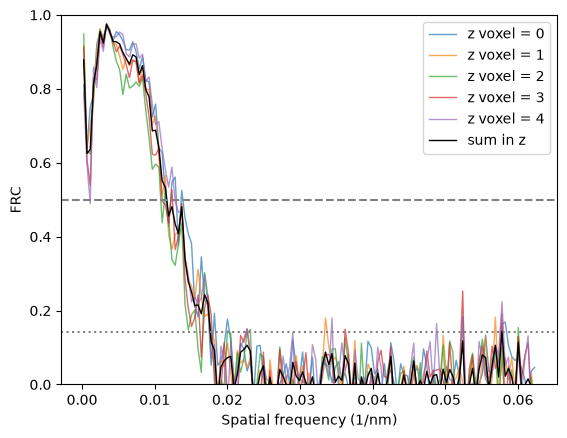

In [167]:
def frc_per_slice(v1, v2, voxel_size):
    nz, ny, nx = v1.shape
    F1, F2 = np.fft.fft2(v1), np.fft.fft2(v2)
    K = np.sqrt(np.fft.fftfreq(ny, voxel_size)[:, None]**2 + np.fft.fftfreq(nx, voxel_size)[None, :]**2)
    n_shells = min(ny, nx) // 2
    edges = np.linspace(0, 0.5 / voxel_size, n_shells + 1)
    freq = 0.5 * (edges[:-1] + edges[1:])
    idx = np.digitize(K.ravel(), edges) - 1
    ok = (idx >= 0) & (idx < n_shells); idx = idx[ok]

    def curve(num, d1, d2):
        n_ = np.bincount(idx, num.ravel()[ok], n_shells)
        a_ = np.bincount(idx, d1.ravel()[ok], n_shells)
        b_ = np.bincount(idx, d2.ravel()[ok], n_shells)
        with np.errstate(invalid="ignore", divide="ignore"):
            return n_ / np.sqrt(a_ * b_)

    num, p1, p2 = (F1 * F2.conj()).real, np.abs(F1)**2, np.abs(F2)**2
    per_slice = [curve(num[z], p1[z], p2[z]) for z in range(nz)]
    pooled = curve(num.sum(0), p1.sum(0), p2.sum(0))
    return freq, per_slice, pooled

freq, per_slice, pooled = frc_per_slice(mx_half1, mx_half2, voxel_nm)
for z, c in enumerate(per_slice):
    plt.plot(freq, c, lw=1, alpha=0.7, label=f"z voxel = {z}")
plt.plot(freq, pooled, "k", lw=1, label="sum in z")
plt.axhline(0.5, ls="--", c="gray"); plt.axhline(0.143, ls=":", c="gray")
plt.ylim(0,1)

plt.xlabel("Spatial frequency (1/nm)"); plt.ylabel("FRC"); plt.legend(); plt.show()

0.6696733204805579


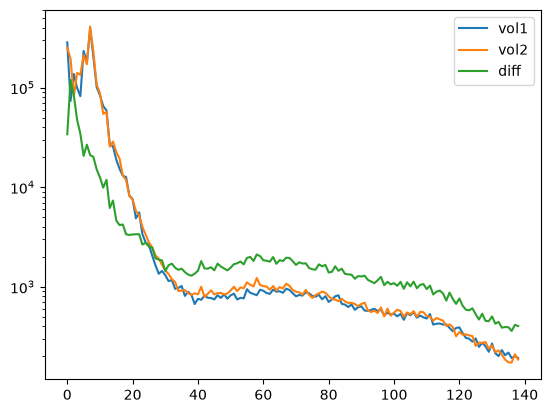

In [168]:
# 1. Are they just nearly identical in real space?
print(np.corrcoef(mx_half1.ravel(), mx_half2.ravel())[0, 1])

# 2. Radial power of vol1, vol2, and their difference
def radial_power(v):
    ny, nx = v.shape[1:]
    F = np.fft.fft2(v - v.mean(axis=(1, 2), keepdims=True))
    P = (np.abs(F)**2).mean(axis=0)
    K = np.hypot(np.fft.fftfreq(ny)[:, None], np.fft.fftfreq(nx)[None, :])
    idx = np.digitize(K.ravel(), np.linspace(0, 0.5, ny//2 + 1)) - 1
    ok = (idx >= 0) & (idx < ny//2)
    return (np.bincount(idx[ok], P.ravel()[ok], ny//2)
            / np.maximum(np.bincount(idx[ok], minlength=ny//2), 1))

for name, v in [("vol1", mx_half1), ("vol2", mx_half2), ("diff", mx_half1 - mx_half2)]:
    plt.semilogy(radial_power(v.astype(float)), label=name)
plt.legend(); plt.show()

(5, 279, 279)
no window number of shells = 139
(5, 279, 279)
no window number of shells = 139


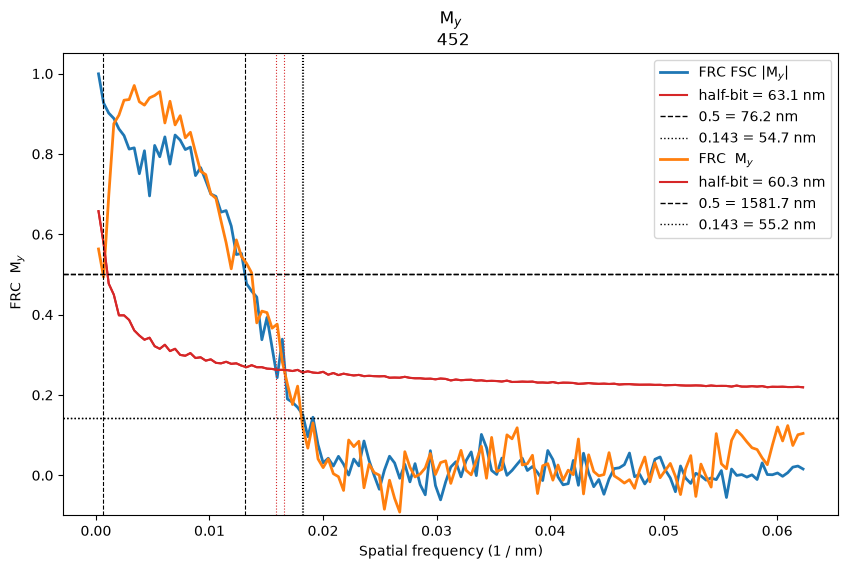

In [169]:
plt.figure(figsize=(10, 6))  

my_half1 = abs(recon_volume_1['My'])
my_half2 = abs(recon_volume_2['My'])
title = f'FSC |M$_y$|'
# freq, fsc, n, res = fourier_shell_correlation(my_half1, my_half2, voxel_nm, sample = sample_name, title = title)
freq, fsc, n, res = frc_stack_no_window(my_half1, my_half2, voxel_nm, sample = sample_name, title = title)


my_half1 = (recon_volume_1['My'])
my_half2 = (recon_volume_2['My'])
title = f' M$_y$'


# freq, fsc, n, res = fourier_shell_correlation(my_half1, my_half2, voxel_nm, sample = sample_name, title = title)

# freq, fsc, n, res = fourier_shell_correlation_bad(mx_half1, mx_half2, voxel_nm, n_shells = 143//2)

# freq, fsc, n, res = fourier_shell_correlation_bad(mx_half1, mx_half2, voxel_nm)

freq, fsc, n, res = frc_stack_no_window(my_half1, my_half2, voxel_nm, sample = sample_name, title = title)
plt.show()


In [170]:
# plt.figure(figsize=(10, 6))  

# my_half1 = abs(recon_volume_1['My'])
# my_half2 = abs(recon_volume_2['My'])
# title = f'FSC |M$_y$|'
# # freq, fsc, n, res = fourier_shell_correlation(mx_half1, mx_half2, voxel_nm, sample = sample_name, title = title)
# freq, fsc, n, res = frc_stack_no_window(my_half1, my_half2, voxel_nm, sample = sample_name, title = title)



# my_half1 = (recon_volume_1['My'])
# my_half2 = (recon_volume_2['My'])
# title = f'FSC M$_y$'

# freq, fsc, n, res = frc_stack_no_window(my_half1, my_half2, voxel_nm, sample = sample_name, title = title)



# # freq, fsc, res05, res0143 = frc_stack(
# #     my_half1,
# #     my_half2,
# #     voxel_size=voxel_nm  
# # )


# # freq, fsc, n, res = fourier_shell_correlation(mx_half1, mx_half2, voxel_nm, sample = sample_name, title = title)

(5, 279, 279)
no window number of shells = 139
(5, 279, 279)
no window number of shells = 139


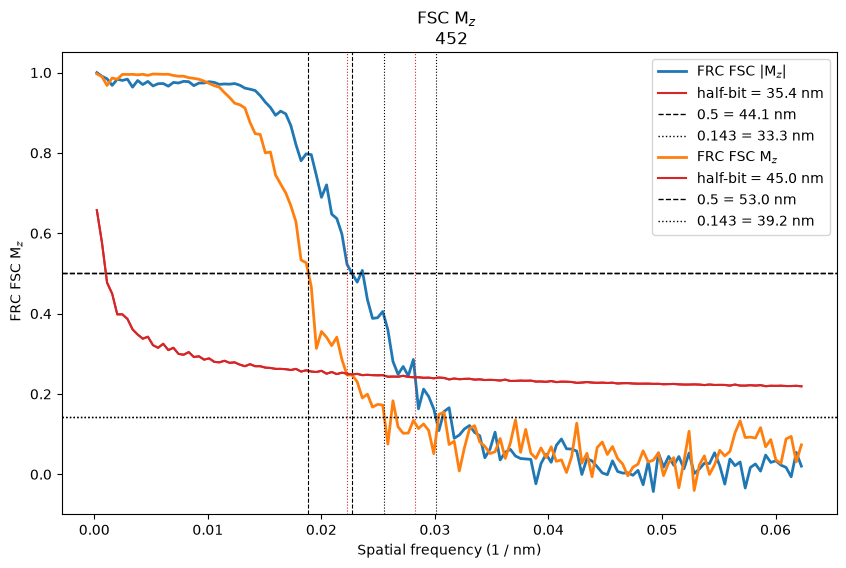

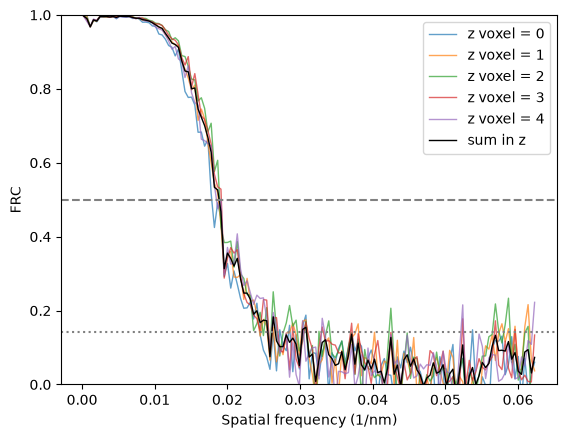

In [171]:
plt.figure(figsize=(10, 6))  

mz_half1 = abs(recon_volume_1['Mz'])
mz_half2 = abs(recon_volume_2['Mz'])
title = f'FSC |M$_z$|'
# freq, fsc, n, res = fourier_shell_correlation(mz_half1, mz_half2, voxel_nm, sample = sample_name, title = title)
freq, fsc, n, res = frc_stack_no_window(mz_half1, mz_half2, voxel_nm, sample = sample_name, title = title)


mz_half1 = (recon_volume_1['Mz'])
mz_half2 = (recon_volume_2['Mz'])
title = f'FSC M$_z$'

# freq, fsc, n, res = fourier_shell_correlation(mz_half1, mz_half2, voxel_nm, sample = sample_name, title = title)
freq, fsc, n, res = frc_stack_no_window(mz_half1, mz_half2, voxel_nm, sample = sample_name, title = title)
plt.show()

freq, per_slice, pooled = frc_per_slice(mz_half1, mz_half2, voxel_nm)
for z, c in enumerate(per_slice):
    plt.plot(freq, c, lw=1, alpha=0.7, label=f"z voxel = {z}")
plt.plot(freq, pooled, "k", lw=1, label="sum in z")
plt.axhline(0.5, ls="--", c="gray"); plt.axhline(0.143, ls=":", c="gray")
plt.ylim(0,1)

plt.xlabel("Spatial frequency (1/nm)"); plt.ylabel("FRC"); plt.legend(); plt.show()


(5, 279, 279)
no window number of shells = 139


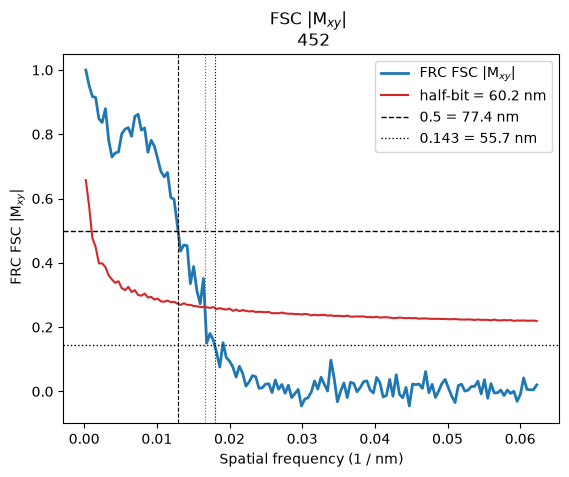

In [172]:
mxy_half1 = np.sqrt(recon_volume_1['Mx']**2 +recon_volume_1['My']**2 )
mxy_half2 = np.sqrt(recon_volume_2['Mx']**2 +recon_volume_2['My']**2 )
title = 'FSC |M$_{xy}$|'
# freq, fsc, n, res = fourier_shell_correlation(mxy_half1, mxy_half2, voxel_nm, sample = sample_name, title = title)
freq, fsc, n, res = frc_stack_no_window(mxy_half1, mxy_half2, voxel_nm, sample = sample_name, title = title)



(5, 279, 279)
no window number of shells = 139


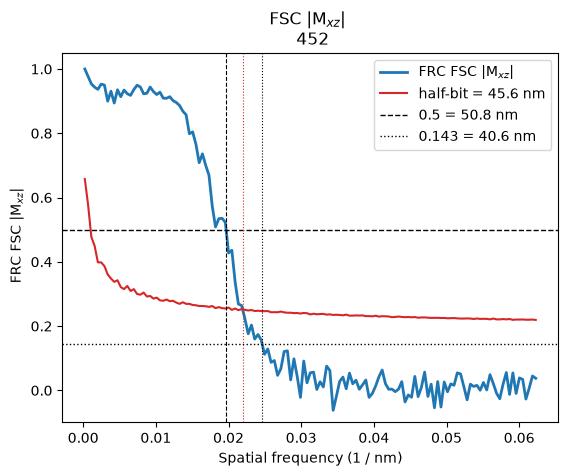

In [173]:
mxz_half1 = np.sqrt(recon_volume_1['Mx']**2 +recon_volume_1['Mz']**2 )
mxz_half2 = np.sqrt(recon_volume_2['Mx']**2 +recon_volume_2['Mz']**2 )
title = 'FSC |M$_{xz}$|'
# freq, fsc, n, res = fourier_shell_correlation(mxz_half1, mxz_half2, voxel_nm, sample = sample_name, title = title)
freq, fsc, n, res = frc_stack_no_window(mxz_half1, mxz_half2, voxel_nm, sample = sample_name, title = title)


(5, 279, 279)
no window number of shells = 139


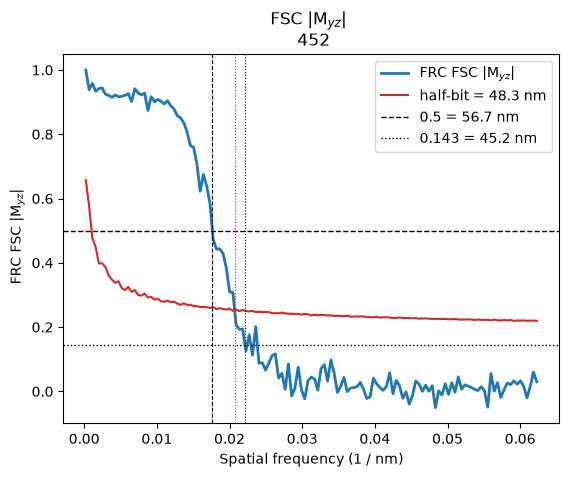

In [174]:
mzy_half1 = np.sqrt(recon_volume_1['My']**2 +recon_volume_1['Mz']**2 )
mzy_half2 = np.sqrt(recon_volume_2['My']**2 +recon_volume_2['Mz']**2 )
title = 'FSC |M$_{yz}$|'
# freq, fsc, n, res = fourier_shell_correlation(mzy_half1, mzy_half2, voxel_nm, sample = sample_name, title = title)
freq, fsc, n, res = frc_stack_no_window(mzy_half1, mzy_half2, voxel_nm, sample = sample_name, title = title)


In [175]:
stop

NameError: name 'stop' is not defined

# Old

In [ ]:
# # Resolution estimates
# def resolution_at_threshold(freq, fsc, threshold):
#     idx = np.where(fsc < threshold)[0]
#     if len(idx) == 0:
#         return np.nan
#     return 1 / freq[idx[0]]

# def fourier_shell_correlation(
#     vol1,
#     vol2,
#     voxel_size,
#     n_shells=150, ######## good assumption based on image size
#     plot=True
# ):
#     """
#     Compute Fourier Shell Correlation (FSC) between two 3D volumes.

#     Parameters
#     ----------
#     vol1, vol2 : ndarray
#         3D numpy arrays (Nz, Ny, Nx)
#     voxel_size : float
#         Voxel size in real space (same units as desired resolution)
#     n_shells : int
#         Number of frequency shells
#     plot : bool
#         Whether to plot FSC curve

#     Returns
#     -------
#     freq : ndarray
#         Spatial frequency (1 / length units)
#     fsc : ndarray
#         FSC values
#     resolution_05 : float
#         Resolution at FSC = 0.5 (same units as voxel_size)
#     resolution_0143 : float
#         Resolution at FSC = 0.143
#     """
#     vol1 = vol1.astype(np.float32)
#     vol2 = vol2.astype(np.float32)
#     assert vol1.shape == vol2.shape, "Volumes must have same shape"

#     # Fourier transforms
#     F1 = np.fft.rfftn(vol1)
#     F2 = np.fft.rfftn(vol2)

#     # Frequency grid
#     nz, ny, nx = vol1.shape
#     kz = np.fft.rfftfreq(nz, d=voxel_size).astype(np.float32)
#     ky = np.fft.rfftfreq(ny, d=voxel_size).astype(np.float32)
#     kx = np.fft.rfftfreq(nx, d=voxel_size).astype(np.float32)
    
#     print(F1.shape)
#     print(len(kz), len(ky), len(kx))

#     # KZ, KY, KX = np.meshgrid(kz, ky, kx, indexing='ij')
#     # K = np.sqrt(KX**2 + KY**2 + KZ**2)

#     # Shell bins
#     k_nyquist_x = np.max((kx))
#     k_nyquist_y = np.max((ky))
#     k_nyquist_z = np.max((kz))

#     k_max = min(k_nyquist_x, k_nyquist_y, k_nyquist_z)
    
#     shell_edges = np.linspace(0, k_max, n_shells + 1)

#     fsc = np.zeros(n_shells, dtype=np.float32)
#     freq = 0.5 * (shell_edges[:-1] + shell_edges[1:])

#     for i in range(n_shells):
#             kmin2 = shell_edges[i]**2
#             kmax2 = shell_edges[i+1]**2

#             num = 0.0
#             den1 = 0.0
#             den2 = 0.0

#             for iz, kzv in enumerate(kz):
#                 kz2 = kzv * kzv
#                 for iy, kyv in enumerate(ky):
#                     ky2 = kyv * kyv
#                     r2 = kz2 + ky2 + kx*kx  # vectorized over x

#                     mask = (r2 >= kmin2) & (r2 < kmax2)
#                     if not np.any(mask):
#                         continue

#                     f1 = F1[iz, iy, mask]
#                     f2 = F2[iz, iy, mask]

#                     num += np.sum(f1 * np.conj(f2)).real
#                     den1 += np.sum(np.abs(f1)**2)
#                     den2 += np.sum(np.abs(f2)**2)

#             fsc[i] = num / np.sqrt(den1 * den2) if den1 > 0 and den2 > 0 else 0
        

# #####################################################################
#     #fsc, freq = compute_fsc(n_shells,shell_edges, F1, F2, K, mask = False )


#     # fsc = np.zeros(n_shells)
#     # freq = np.zeros(n_shells)

#     # # min_voxels = 50  # or something reasonable
#     # # valid_shells = []

#     # for i in range(n_shells):
#     #     shell_mask = (K >= shell_edges[i]) & (K < shell_edges[i + 1])

#     #     # if np.count_nonzero(shell_mask) < min_voxels:
#     #     #     break
#     #     # valid_shells.append(i)
        
#     #     F1_shell = F1[shell_mask]
#     #     F2_shell = F2[shell_mask]

#     #     if F1_shell.size == 0:
#     #         fsc[i] = np.nan
#     #         continue

#     #     num = np.sum(F1_shell * np.conj(F2_shell))
#     #     den = np.sqrt(
#     #         np.sum(np.abs(F1_shell)**2) *
#     #         np.sum(np.abs(F2_shell)**2)
#     #     )

#     #     fsc[i] = np.real(num / den)
#     #     freq[i] = 0.5 * (shell_edges[i] + shell_edges[i + 1])
# #####################################################################

#     resolution_05 = resolution_at_threshold(freq, fsc, 0.5)
#     resolution_0143 = resolution_at_threshold(freq, fsc, 0.143)
#     print(f"Resolution (FSC=0.5): {resolution_05:.1f} nm")
#     print(f"Resolution (FSC=0.143): {resolution_0143:.1f} nm")
    
#     if plot:
#         plt.figure(figsize=(6, 4))
#         plt.plot(freq, fsc, lw=2)
#         plt.axhline(0.5, ls='--', color='k', label=f'0.5, res = {resolution_05:.2f}')
#         plt.axhline(0.143, ls=':', color='k', label=f'0.143, res = {resolution_0143:.2f}')

#         if not np.isnan(resolution_05):
#             plt.axvline(1 / resolution_05, ls='--', color='k')
#         if not np.isnan(resolution_0143):
#             plt.axvline(1 / resolution_0143, ls=':', color='k')

#         plt.xlabel('Spatial frequency (1 / nm)')
#         plt.ylabel('FSC')
#         plt.ylim(-0.1, 1.05)
#         plt.legend()
#         plt.tight_layout()
#         plt.show()
        
#         mid_z = F1.shape[0] // 2
#         F1_slice = np.fft.fftshift(F1[mid_z], axes=(0,))
#         F2_slice = np.fft.fftshift(F2[mid_z], axes=(0,))
#         ky = np.fft.fftshift(ky)
        
#         extent = [
#             kx[0], kx[-1],     # x-axis (horizontal)
#             ky[0], ky[-1]      # y-axis (vertical)
#         ]

#         plt.imshow(
#             np.log(np.abs(F1_slice)),
#             extent=extent,
#             origin='lower',
#             aspect='auto',
#             cmap='viridis'
#         )

#         plt.xlabel(r"$k_x$ (nm$^{-1}$)")
#         plt.ylabel(r"$k_y$ (nm$^{-1}$)")
#         plt.title("FT magnitude Volume 1")
#         plt.colorbar(label="log |F(k)|")
#         plt.show()
        
#         plt.imshow(
#             np.log(np.abs(F2_slice)),
#             extent=extent,
#             origin='lower',
#             aspect='auto',
#             cmap='viridis'
#         )

#         plt.xlabel(r"$k_x$ (nm$^{-1}$)")
#         plt.ylabel(r"$k_y$ (nm$^{-1}$)")
#         plt.title("FT magnitude Volume 2")
#         plt.colorbar(label="log |F(k)|")
#         plt.show()
        
        
#     return freq, fsc, resolution_05, resolution_0143

In [ ]:
### Functions

def plot_crosssections (k, reconstruction): 
  
    #  # --- Extract Nx, Ny ---
    # Nz, Ny, Nx = reconstruction.shape 

    # --- Define physical extent in μm ---
    FOV_x = 4.0  # μm
    FOV_y = 4.0  # μm

    extent = [0, FOV_x, 0, FOV_y]  # [xmin, xmax, ymin, ymax] in μm

    # Tick positions every 1 μm
    ticks_um = np.arange(0, (FOV_x+0.1), 1.0)

    # --- Plot ---
    fig = plt.figure(figsize=(10, 6))
    
    if Gamma == 'Gamma0':
        fig.suptitle(f"Sample {sample}, Γ = 0", fontsize=16, y=0.8)
        
    # fig.tight_layout()
    
    ax1 = fig.add_subplot(1, 3, 1)
    ax1.imshow(reconstruction[k,:,:], extent = extent, origin = 'lower')
    ax1.set_title(f'YX')
    ax1.set_ylabel("(μm)")
    ax1.set_yticks(ticks_um)
    ax1.set_xlabel("(μm)")
    ax1.set_xticks(ticks_um)
    
    ax2 = fig.add_subplot(1, 3, 2)
    ax2.imshow(reconstruction[:,k,:], extent = extent, origin = 'lower')
    ax2.set_title('ZX')
    ax2.set_ylabel("(μm)")
    ax2.set_yticks(ticks_um)
    ax2.set_xlabel("(μm)")
    ax2.set_xticks(ticks_um)
    
    ax3 = fig.add_subplot(1, 3, 3)
    ax3.imshow(reconstruction[:,:,k], extent = extent, origin = 'lower')
    ax3.set_title('ZY')
    ax3.set_ylabel("(μm)")
    ax3.set_yticks(ticks_um)
    ax3.set_xlabel("(μm)")
    ax3.set_xticks(ticks_um)
    
    # fig.subplots_adjust(top=0.5)  # make room for suptitle

    # fig.tight_layout()
    
    
def estimate_rotation(img_ref, img_mov):
    F1 = np.abs(fftshift(fft2(img_ref)))
    F2 = np.abs(fftshift(fft2(img_mov)))

    radius = min(img_ref.shape) // 2

    W1 = warp_polar(F1, radius=radius)
    W2 = warp_polar(F2, radius=radius)

    shift, error, _ = phase_cross_correlation(W1, W2)
    rotation = shift[0] * 360 / W1.shape[0]

    return rotation

def crop_center(img, cy, cx, half):
    y0 = max(cy - half, 0)
    y1 = min(cy + half, img.shape[0])
    x0 = max(cx - half, 0)
    x1 = min(cx + half, img.shape[1])
    return img[y0:y1, x0:x1]

# ## Rotate the projection 90 degrees so that the axis of rotation is vertical
# rotated_0 = rotate(proj_0,angle=90,axes=(1, 2),reshape=False, order=1)
# print(rotated_0.shape)

def reconstruct_and_save(proj_sub, ang_sub, center, tag, save = True):
    """
    proj_sub : (n, ny, nx)
    ang_sub  : (n,)
    tag      : descriptive string for saving
    """
    print(f"{tag}: using {len(ang_sub)} angles")

    # recon = tomopy.recon(proj_sub, ang_sub, algorithm='gridrec', sinogram_order=False)

    recon = tomopy.recon(proj_sub, ang_sub, center=center, algorithm='gridrec', sinogram_order=False) ### 
    recon = tomopy.circ_mask(recon, axis=0, ratio=0.90) 

    if save:
        tifffile.imwrite(f"{Gamma}_{tag}.tif", recon.astype(np.float32))
        print('saved')

    return recon


def rotate_about_COR(image, rotation_angle, y_centroid, x_centroid, order=1, plot = True):
    '''
    Can only rotate one image at a time
    '''
    ny, nx = image.shape

    # image center
    cy = (ny) / 2
    cx = (nx) / 2
    
    # shift needed to bring centroid to image center (unrotated coordinates)
    shift_to_center = (cy - y_centroid, cx - x_centroid)
    # print(shift_to_center)
    
    # 1. shift centroid to center (x and y)
    img_shifted = shift(image, shift=shift_to_center, order=order, mode='constant')
    
    # 2. rotate about center
    rotated_img = rotate(img_shifted, angle=rotation_angle, reshape=True, order=order)

    ## shift centroid by 90
    x_cent_rot = y_centroid
    y_cent_rot = ny - x_centroid

    # 3. shift back
    img_final = shift(rotated_img, shift=(-shift_to_center[0], -shift_to_center[1]),
                      order=order, mode='constant')

    if plot == True:
        
        fig = plt.figure(figsize=(15, 6))
        ax1 = fig.add_subplot(1, 3, 1)
        ax1.imshow(image)
        ax1.axhline(y=cy, color='b', linewidth=2)
        ax1.axvline(x=cx, color='b', linewidth=2)
        ax1.plot(cx, cy, 'bs', markersize=10, label = f'image center \n ({cx}, {cy})')
        ax1.plot(x_centroid, y_centroid, 'ro', markersize=10, label = f'centroid \n ({x_centroid}, {y_centroid})')
        #ax1.plot(x_centroid-shift_to_center[0], y_centroid-shift_to_center[1], 'g^', markersize=10, label = f'centroid shift to center /n ({x_centroid-shift_to_center[0]}, {y_centroid-shift_to_center[1]})')
        ax1.legend(loc= 'upper left')
        ax1.set_title(f'Gamma {Gamma}, alpha = {ang_deg[k]:.2f}, unrotated')

        ax2 = fig.add_subplot(1, 3, 2)
        ax2.imshow(img_shifted)
        #ax2.plot(x_centroid, y_centroid, 'ro', markersize=10, label = f'centroid \n ({x_centroid}, {y_centroid})')
        ax2.axhline(y=cy, color='b', linewidth=2)
        ax2.axvline(x=cx, color='b', linewidth=2)
        ax2.plot(cx, cy, 'bs', markersize=10, label = f'old image center \n ({cx}, {cy})')
        ax2.plot(x_centroid+shift_to_center[1], y_centroid+shift_to_center[0], 'ro', markersize=10, label = f'centroid shifted to center \n ({x_centroid+shift_to_center[1]}, {y_centroid+shift_to_center[0]})')
        ax2.set_title(f'Gamma {Gamma} shifted')
        ax2.legend(loc= 'upper left')

        ax3 = fig.add_subplot(1, 3, 3)
        ax3.imshow(rotated_img)
        #ax3.plot(x_centroid, y_centroid, 'ro', markersize=10, label = f'centroid \n ({x_centroid},{ y_centroid})')
        ax3.plot(cx, cy, 'bs', markersize=10, label = f'old image center \n ({cx}, {cy})')
        ax3.axhline(y=cy, color='b', linewidth=2)
        ax3.axvline(x=cx, color='b', linewidth=2)
        ax3.plot(x_centroid+shift_to_center[1], y_centroid+shift_to_center[0], 'ro', markersize=10, label = f'centroid shift to center \n ({x_centroid+shift_to_center[1]}, {y_centroid+shift_to_center[0]})')
        ax3.set_title(f'Gamma {Gamma} rotated')
        ax3.legend()

        # ax4 = fig.add_subplot(2, 2, 4)
        # ax4.imshow(img_final)
        # ax4.plot(x_cent_rot, y_cent_rot, 'g^', markersize=10, label = f'centroid rotated by 90 deg. \n ({x_cent_rot},{ y_cent_rot})')
        # #ax4.plot(x_centroid-shift_to_center[0], y_centroid-shift_to_center[1], 'g^', markersize=10, label = f'centroid shift to center \n ({x_centroid-shift_to_center[1]}, {y_centroid-shift_to_center[0]})')
        # ax4.plot(cx, cy, 'bs', markersize=10, label = f'old image center \n ({cx}, {cy})')
        # ax4.plot(x_centroid+shift_to_center[1], y_centroid+shift_to_center[0], 'ro', markersize=10, label = f'centroid shift to center \n ({x_centroid+shift_to_center[1]}, {y_centroid+shift_to_center[0]})')
        # ax4.plot(cx, cy, 'bs', markersize=10, label = f'old image center \n ({cx}, {cy})')
        # ax4.set_title(f'Gamma {Gamma} rotated')
        # ax4.legend()
        

    return rotated_img

In [ ]:
# Resolution estimates
def resolution_at_threshold(freq, fsc, threshold):
    idx = np.where(fsc < threshold)[0]
    if len(idx) == 0:
        return np.nan
    return 1 / freq[idx[0]]


def compute_fsc(n_shells,shell_edges, F1, F2, K, mask =False):
    fsc = np.zeros(n_shells)
    freq = np.zeros(n_shells)
    for i in range(n_shells):
        if mask==True:
            shell = (K >= shell_edges[i]) & (K < shell_edges[i+1]) & mask
        if mask == False:
            shell = (K >= shell_edges[i]) & (K < shell_edges[i+1])
        F1_shell = F1[shell]
        F2_shell = F2[shell]

        if F1.size < 10: ### why 10?
            fsc[i] = np.nan
            continue
        
        if F1_shell.size == 0:
            fsc[i] = np.nan
            continue

        num = np.sum(F1_shell * np.conj(F2_shell))
        den = np.sqrt(
            np.sum(np.abs(F1_shell)**2) *
            np.sum(np.abs(F2_shell)**2)
        )
        fsc[i] = np.real(num / den)
        freq[i] = 0.5 * (shell_edges[i] + shell_edges[i + 1])
        
    return fsc, freq
    
    
def fourier_shell_correlation(
    vol1,
    vol2,
    voxel_size,
    n_shells=150, ######## good assumption based on image size
    plot=True
):
    """
    Compute Fourier Shell Correlation (FSC) between two 3D volumes.

    Parameters
    ----------
    vol1, vol2 : ndarray
        3D numpy arrays (Nz, Ny, Nx)
    voxel_size : float
        Voxel size in real space (same units as desired resolution)
    n_shells : int
        Number of frequency shells
    plot : bool
        Whether to plot FSC curve

    Returns
    -------
    freq : ndarray
        Spatial frequency (1 / length units)
    fsc : ndarray
        FSC values
    resolution_05 : float
        Resolution at FSC = 0.5 (same units as voxel_size)
    resolution_0143 : float
        Resolution at FSC = 0.143
    """
    vol1 = vol1.astype(np.float32)
    vol2 = vol2.astype(np.float32)
    assert vol1.shape == vol2.shape, "Volumes must have same shape"

    # Fourier transforms
    F1 = np.fft.rfftn(vol1)
    F2 = np.fft.rfftn(vol2)

    # Frequency grid
    nz, ny, nx = vol1.shape
    kz = np.fft.rfftfreq(nz, d=voxel_size).astype(np.float32)
    ky = np.fft.rfftfreq(ny, d=voxel_size).astype(np.float32)
    kx = np.fft.rfftfreq(nx, d=voxel_size).astype(np.float32)
    
    print(F1.shape)
    print(len(kz), len(ky), len(kx))

    # KZ, KY, KX = np.meshgrid(kz, ky, kx, indexing='ij')
    # K = np.sqrt(KX**2 + KY**2 + KZ**2)

    # Shell bins
    k_nyquist_x = np.max((kx))
    k_nyquist_y = np.max((ky))
    k_nyquist_z = np.max((kz))

    k_max = min(k_nyquist_x, k_nyquist_y, k_nyquist_z)
    
    shell_edges = np.linspace(0, k_max, n_shells + 1)

    fsc = np.zeros(n_shells, dtype=np.float32)
    freq = 0.5 * (shell_edges[:-1] + shell_edges[1:])

    for i in range(n_shells):
            kmin2 = shell_edges[i]**2
            kmax2 = shell_edges[i+1]**2

            num = 0.0
            den1 = 0.0
            den2 = 0.0

            for iz, kzv in enumerate(kz):
                kz2 = kzv * kzv
                for iy, kyv in enumerate(ky):
                    ky2 = kyv * kyv
                    r2 = kz2 + ky2 + kx*kx  # vectorized over x

                    mask = (r2 >= kmin2) & (r2 < kmax2)
                    if not np.any(mask):
                        continue

                    f1 = F1[iz, iy, mask]
                    f2 = F2[iz, iy, mask]

                    num += np.sum(f1 * np.conj(f2)).real
                    den1 += np.sum(np.abs(f1)**2)
                    den2 += np.sum(np.abs(f2)**2)

            fsc[i] = num / np.sqrt(den1 * den2) if den1 > 0 and den2 > 0 else 0
        

#####################################################################
    #fsc, freq = compute_fsc(n_shells,shell_edges, F1, F2, K, mask = False )


    # fsc = np.zeros(n_shells)
    # freq = np.zeros(n_shells)

    # # min_voxels = 50  # or something reasonable
    # # valid_shells = []

    # for i in range(n_shells):
    #     shell_mask = (K >= shell_edges[i]) & (K < shell_edges[i + 1])

    #     # if np.count_nonzero(shell_mask) < min_voxels:
    #     #     break
    #     # valid_shells.append(i)
        
    #     F1_shell = F1[shell_mask]
    #     F2_shell = F2[shell_mask]

    #     if F1_shell.size == 0:
    #         fsc[i] = np.nan
    #         continue

    #     num = np.sum(F1_shell * np.conj(F2_shell))
    #     den = np.sqrt(
    #         np.sum(np.abs(F1_shell)**2) *
    #         np.sum(np.abs(F2_shell)**2)
    #     )

    #     fsc[i] = np.real(num / den)
    #     freq[i] = 0.5 * (shell_edges[i] + shell_edges[i + 1])
#####################################################################

    resolution_05 = resolution_at_threshold(freq, fsc, 0.5)
    resolution_0143 = resolution_at_threshold(freq, fsc, 0.143)
    print(f"Resolution (FSC=0.5): {resolution_05:.1f} nm")
    print(f"Resolution (FSC=0.143): {resolution_0143:.1f} nm")
    
    if plot:
        plt.figure(figsize=(6, 4))
        plt.plot(freq, fsc, lw=2)
        plt.axhline(0.5, ls='--', color='k', label=f'0.5, res = {resolution_05:.2f}')
        plt.axhline(0.143, ls=':', color='k', label=f'0.143, res = {resolution_0143:.2f}')

        if not np.isnan(resolution_05):
            plt.axvline(1 / resolution_05, ls='--', color='k')
        if not np.isnan(resolution_0143):
            plt.axvline(1 / resolution_0143, ls=':', color='k')

        plt.xlabel('Spatial frequency (1 / nm)')
        plt.ylabel('FSC')
        plt.ylim(-0.1, 1.05)
        plt.legend()
        plt.tight_layout()
        plt.show()
        
        mid_z = F1.shape[0] // 2
        F1_slice = np.fft.fftshift(F1[mid_z], axes=(0,))
        F2_slice = np.fft.fftshift(F2[mid_z], axes=(0,))
        ky = np.fft.fftshift(ky)
        
        extent = [
            kx[0], kx[-1],     # x-axis (horizontal)
            ky[0], ky[-1]      # y-axis (vertical)
        ]

        plt.imshow(
            np.log(np.abs(F1_slice)),
            extent=extent,
            origin='lower',
            aspect='auto',
            cmap='viridis'
        )

        plt.xlabel(r"$k_x$ (nm$^{-1}$)")
        plt.ylabel(r"$k_y$ (nm$^{-1}$)")
        plt.title("FT magnitude Volume 1")
        plt.colorbar(label="log |F(k)|")
        plt.show()
        
        plt.imshow(
            np.log(np.abs(F2_slice)),
            extent=extent,
            origin='lower',
            aspect='auto',
            cmap='viridis'
        )

        plt.xlabel(r"$k_x$ (nm$^{-1}$)")
        plt.ylabel(r"$k_y$ (nm$^{-1}$)")
        plt.title("FT magnitude Volume 2")
        plt.colorbar(label="log |F(k)|")
        plt.show()
        
        
    return freq, fsc, resolution_05, resolution_0143





In [ ]:

    
def directional_fsc(
    vol1,
    vol2,
    voxel_size,
    n_shells=100,
    cone_angle_deg=20,
    plot=True
):
    """
    Compute directional FSC: in-plane (xy) vs axial (z).

    Parameters
    ----------
    vol1, vol2 : ndarray
        3D reconstructed volumes
    voxel_size : float
        Real-space voxel size
    n_shells : int
        Number of Fourier shells
    cone_angle_deg : float
        Half-angle of directional cone (degrees)
    plot : bool
        Plot FSC curves

    Returns
    -------
    freq : ndarray
        Spatial frequency
    fsc_xy : ndarray
        In-plane FSC
    fsc_z : ndarray
        Axial FSC
    """

    assert vol1.shape == vol2.shape

    # n-dimensional discrete FT over all axes
    F1 = np.fft.fftn(vol1)
    F2 = np.fft.fftn(vol2)

    nz, ny, nx = vol1.shape

    ## FT of sample frequencies, n = window length and d = sample spacing, should be related to voxel size
    kz = np.fft.fftfreq(nz, d=voxel_size)
    ky = np.fft.fftfreq(ny, d=voxel_size)
    kx = np.fft.fftfreq(nx, d=voxel_size)

    KZ, KY, KX = np.meshgrid(kz, ky, kx, indexing='ij')
    K = np.sqrt(KX**2 + KY**2 + KZ**2)

    # Avoid divide-by-zero
    with np.errstate(divide='ignore', invalid='ignore'):
        cos_theta = np.abs(KZ) / K

    theta = np.arccos(cos_theta) * 180 / np.pi

    alpha = cone_angle_deg

    mask_xy = theta > (90 - alpha)   # in-plane
    mask_z  = theta < alpha          # axial

    # Shell bins
    k_nyquist_x = np.max(np.abs(kx))
    k_nyquist_y = np.max(np.abs(ky))
    k_nyquist_z = np.max(np.abs(kz))

    k_max = min(k_nyquist_x, k_nyquist_y, k_nyquist_z)
    shell_edges = np.linspace(0, k_max, n_shells + 1)

    # fsc_xy = np.zeros(n_shells)
    # fsc_z  = np.zeros(n_shells)
    # freq   = np.zeros(n_shells)
    
    fsc_xy, freq_xy = compute_fsc(n_shells,shell_edges, F1, F2, K, mask = mask_xy )
    fsc_z, freq_z = compute_fsc(n_shells,shell_edges, F1, F2, K, mask = mask_z )

    # for i in range(n_shells):
    #     freq[i] = 0.5 * (shell_edges[i] + shell_edges[i+1])

    if plot:
        plt.figure(figsize=(6, 4))
        plt.plot(freq_xy, fsc_xy, label='In-plane (xy)', lw=2)
        plt.plot(freq_z, fsc_z, label='Axial (z)', lw=2)
        
        plt.axhline(0.5, ls='--', color='k', label='0.5')
        plt.axhline(0.143, ls=':', color='k', label='0.143')

        # if not np.isnan(resolution_05):
        #     plt.axvline(1 / resolution_05, ls='--', color='k')
        # if not np.isnan(resolution_0143):
        #     plt.axvline(1 / resolution_0143, ls=':', color='k')

        plt.xlabel('Spatial frequency (1 / nm)')
        plt.ylabel('FSC')
        plt.ylim(-0.1, 1.05)
        plt.legend()
        plt.tight_layout()
        plt.show()

    return freq_xy, freq_z, fsc_xy, fsc_z

def spiral_directions(n_dirs):
    """
    Generate approximately uniform directions on the unit sphere
    using the Saff–Kuijlaars spiral algorithm.
    """
    dirs = np.zeros((n_dirs, 3))
    golden_angle = np.pi * (3 - np.sqrt(5))

    for i in range(n_dirs):
        z = 1 - (2*i + 1)/n_dirs
        r = np.sqrt(1 - z*z)
        phi = i * golden_angle
        dirs[i] = [r*np.cos(phi), r*np.sin(phi), z]

    return dirs

def frequency_grid(shape, voxel_size):
    """
    ## FT of sample frequencies, n = window length and d = sample spacing, should be related to voxel size
    """
    nx, ny, nz = shape
    kz = np.fft.fftfreq(nz, d=voxel_size)
    ky = np.fft.fftfreq(ny, d=voxel_size)
    kx = np.fft.fftfreq(nx, d=voxel_size)

    KZ, KY, KX = np.meshgrid(kz, ky, kx, indexing='ij')
    K = np.sqrt(KX**2 + KY**2 + KZ**2)
    
    # ignore edge/corner effects
    k_nyquist_x = np.max(np.abs(kx))
    k_nyquist_y = np.max(np.abs(ky))
    k_nyquist_z = np.max(np.abs(kz))

    k_max = min(k_nyquist_x, k_nyquist_y, k_nyquist_z)
    
    # unit vectors (avoid divide-by-zero)
    eps = 1e-12
    kx = KX / (K + eps)
    ky = KY / (K + eps)
    kz = KZ / (K + eps)

    return K, k_max, np.stack((kx, ky, kz), axis=-1)

def cone_fsc(vol1, vol2, voxel_size=8e-9,
             n_dirs=100, sigma_f=None, sigma_c=None,
             fsc_threshold=0.143):
    """
    Compute anisotropic (cone-based) FSC.
    """

    # 1. Take FFT of both volumes
    F1 = fftshift(fftn(vol1))
    F2 = fftshift(fftn(vol2))

    # 2. define the reciprocal space grid, ensuring that edges are handled, etc. 
    shape = vol1.shape
    K, k_max, k_hat = frequency_grid(shape, voxel_size)

    # 3. Radial sampling
    n_shells = min(shape)//2 
    print(f'number of shells = {n_shells}')
    shell_edges = np.linspace(0, k_max, n_shells + 1)
    print(f'shape of shell edges = {shell_edges.shape}')

    # 3a. in the Gaussian sampling profile, sigma_f controls width of the profile and coincides with the distances between subsequent rings (df) 
    df = shell_edges[1] - shell_edges[0]
    if sigma_f is None:
        sigma_f = df
        print(f'sigma_f = {sigma_f}')
        
    # 3b. for the angular dependence, sigma_c is is set to average the distance between neighboring sample orientations 
    if sigma_c is None:
        sigma_c = np.deg2rad(n_dirs/10)  # ~ average angular spacing for 100 cones
        print(f'sigma_c = {sigma_c} for number of cones {n_dirs}/10 = {n_dirs/10}')

    # 3c.  the sample orientation are chosen for a given number by the spiral point algorithm from Saff and Kuijlaars 
    directions = spiral_directions(n_dirs)
    print(f'spiroal point algorithm directions {directions.shape}')

    fsc_dirs = []
    res_dirs = []

    for d in directions:
        # angular distance
        cosang = (k_hat[...,0]*d[0] +
                  k_hat[...,1]*d[1] +
                  k_hat[...,2]*d[2])
        ang_phi = np.arccos(np.clip(cosang, -1, 1))

        fsc_curve = []

        for k0 in shell_edges:
            w_r = np.exp(-(K - k0)**2 / (2*sigma_f**2))
            w_c = np.exp(-(ang_phi)**2 / (2*sigma_c**2))
            w = w_r * w_c

            num = np.sum(w * F1 * np.conj(F2))
            den = np.sqrt(
                np.sum(w * np.abs(F1)**2) *
                np.sum(w * np.abs(F2)**2)
            )

            fsc_curve.append(np.real(num / den) if den > 0 else 0)

        fsc_curve = np.array(fsc_curve)
        fsc_dirs.append(fsc_curve)

        # Resolution from FSC threshold
        idx = np.where(fsc_curve < fsc_threshold)[0]
        if len(idx) > 0 and shell_edges[idx[0]] > 0:
            res_dirs.append(1 / shell_edges[idx[0]])
        else:
            res_dirs.append(np.nan)

    return shell_edges, np.array(fsc_dirs), np.array(res_dirs), directions

def split_inplane_outofplane(directions, resolutions, axis=np.array([0,0,1])):
    """
    Separate in-plane and out-of-plane resolution.
    """
    cosang = np.abs(directions @ axis)
    in_plane = resolutions[cosang < 0.3]
    out_plane = resolutions[cosang > 0.7]

    return np.nanmean(in_plane), np.nanmean(out_plane)

def plot_directional_fsc(freqs, fsc_dirs):
    plt.figure(figsize=(6,4))
    for fsc in fsc_dirs:
        plt.plot(freqs, fsc, alpha=0.2)
    plt.axhline(0.143, color='k', linestyle='--')
    plt.xlabel('Spatial frequency (1/m)')
    plt.ylabel('FSC')
    plt.title('Directional FSC')
    plt.show()

def plot_resolution_sphere(directions, resolutions):
    fig = plt.figure(figsize=(6,6))
    ax = fig.add_subplot(111, projection='3d')

    sc = ax.scatter(directions[:,0],
                    directions[:,1],
                    directions[:,2],
                    c=resolutions,
                    cmap='viridis')

    plt.colorbar(sc, label='Resolution (m)')
    ax.set_title('Anisotropic Resolution Map')
    plt.show()


# FSC 

## Depth Dependent 

In [ ]:
def fourier_shell_correlation_zdir(
    vol1,
    vol2,
    voxel_size,
    n_shells=150, ######## good assumption based on image size
    plot=True
):
    """
    Compute Fourier Shell Correlation (FSC) between two 3D volumes.

    Parameters
    ----------
    vol1, vol2 : ndarray
        3D numpy arrays (Nz, Ny, Nx)
    voxel_size : float
        Voxel size in real space (same units as desired resolution)
    n_shells : int
        Number of frequency shells
    plot : bool
        Whether to plot FSC curve

    Returns
    -------
    freq : ndarray
        Spatial frequency (1 / length units)
    fsc : ndarray
        FSC values
    resolution_05 : float
        Resolution at FSC = 0.5 (same units as voxel_size)
    resolution_0143 : float
        Resolution at FSC = 0.143
    """

    assert vol1.shape == vol2.shape, "Volumes must have same shape"

    # Fourier transforms
    F1 = np.fft.fftn(vol1)
    F2 = np.fft.fftn(vol2)

    # Frequency grid
    nz, ny, nx = vol1.shape
    kz = np.fft.fftfreq(nz, d=voxel_size).astype(np.float32)
    ky = np.fft.fftfreq(ny, d=voxel_size).astype(np.float32)
    kx = np.fft.fftfreq(nx, d=voxel_size).astype(np.float32)
    
    print(F1.shape)
    print(len(kz), len(ky), len(kx))
    
    
    # Shell bins
    k_nyquist_x = np.max((kx))
    k_nyquist_y = np.max((ky))
    k_nyquist_z = np.max((kz))

    k_max = min(k_nyquist_x, k_nyquist_y, k_nyquist_z)
    

    # KZ, KY, KX = np.meshgrid(kz, ky, kx, indexing='ij')
    # K = np.sqrt(KX**2 + KY**2 + KZ**2)

    ## frequency direction 
    freq_dir = np.abs(k_nyquist_z)
    max_freq = np.max(freq_dir)

    # Shell bins
    shell_edges = np.linspace(0, max_freq, n_shells + 1)

    fsc = np.zeros(n_shells, dtype=np.float32)
    #freq = np.zeros(n_shells)
    freq = 0.5 * (shell_edges[:-1] + shell_edges[1:])

    for i in range(n_shells):
            kmin2 = shell_edges[i]**2
            kmax2 = shell_edges[i+1]**2

            num = 0.0
            den1 = 0.0
            den2 = 0.0

            for iz, kzv in enumerate(kz):
                kz2 = kzv * kzv
                for iy, kyv in enumerate(ky):
                    ky2 = kyv * kyv
                    r2 = kz2 + ky2 + kx*kx  # vectorized over x

                    mask = (r2 >= kmin2) & (r2 < kmax2)
                    if not np.any(mask):
                        continue

                    f1 = F1[iz, iy, mask]
                    f2 = F2[iz, iy, mask]

                    num += np.sum(f1 * np.conj(f2)).real
                    den1 += np.sum(np.abs(f1)**2)
                    den2 += np.sum(np.abs(f2)**2)

            fsc[i] = num / np.sqrt(den1 * den2) if den1 > 0 and den2 > 0 else 0


    resolution_05 = resolution_at_threshold(freq, fsc, 0.5)
    resolution_0143 = resolution_at_threshold(freq, fsc, 0.143)

    
    if plot:
        plt.figure(figsize=(6, 4))
        plt.plot(freq, fsc, lw=2)
        plt.axhline(0.5, ls='--', color='k', label=f'0.5, res = {resolution_05:.2f}')
        plt.axhline(0.143, ls=':', color='k', label=f'0.143, res = {resolution_0143:.2f}')

        if not np.isnan(resolution_05):
            plt.axvline(1 / resolution_05, ls='--', color='k')
        if not np.isnan(resolution_0143):
            plt.axvline(1 / resolution_0143, ls=':', color='k')

        plt.xlabel('Spatial frequency (1 / nm)')
        plt.ylabel('FSC')
        plt.ylim(-0.1, 1.05)
        plt.legend()
        plt.tight_layout()
        plt.show()
        
        # mid_z = F1.shape[0] // 2
        # F1_slice = np.fft.fftshift(F1[mid_z], axes=(0,))
        # F2_slice = np.fft.fftshift(F2[mid_z], axes=(0,))
        # ky = np.fft.fftshift(ky)
        
        # extent = [
        #     kx[0], kx[-1],     # x-axis (horizontal)
        #     ky[0], ky[-1]      # y-axis (vertical)
        # ]

        # plt.imshow(
        #     np.log(np.abs(F1_slice)),
        #     extent=extent,
        #     origin='lower',
        #     aspect='auto',
        #     cmap='viridis'
        # )

        # plt.xlabel(r"$k_x$ (nm$^{-1}$)")
        # plt.ylabel(r"$k_y$ (nm$^{-1}$)")
        # plt.title("FT magnitude Volume 1")
        # plt.colorbar(label="log |F(k)|")
        # plt.show()
        
        # plt.imshow(
        #     np.log(np.abs(F2_slice)),
        #     extent=extent,
        #     origin='lower',
        #     aspect='auto',
        #     cmap='viridis'
        # )

        # plt.xlabel(r"$k_x$ (nm$^{-1}$)")
        # plt.ylabel(r"$k_y$ (nm$^{-1}$)")
        # plt.title("FT magnitude Volume 2")
        # plt.colorbar(label="log |F(k)|")
        # plt.show()
        
    return freq, fsc, resolution_05, resolution_0143



In [ ]:
## Take the reconstruction of two volumes with half of the angles
voxel_size_1D = 8 # [nm] from meta data
yo_rot = center2
# seperate first half
proj_half1 = rotated[::2]
ang_half1 = ang[::2]
# second half 
proj_half2 = rotated[1::2]
ang_half2  = ang[1::2]

print(len(rotated), len(proj_half1), len(proj_half2))
print(len(ang), len(ang_half1), len(ang_half2))

## Reconstruct 
recon_half1 = reconstruct_and_save(proj_half1, ang_half1, yo_rot, tag="first half", save = False)
recon_half2 = reconstruct_and_save(proj_half2, ang_half2, yo_rot, tag="second half", save = False)

freqs_z, fsc_dirs_z, res_dirs_z, res_143_dirs_z = fourier_shell_correlation_zdir(
    recon_half1, recon_half2,
    voxel_size=voxel_size_1D,
    n_shells=100,
    plot = True
)

# plot_directional_fsc(freqs_z, fsc_dirs_z)
# plot_resolution_sphere(dirs, res_dirs)

# res_in, res_out = split_inplane_outofplane(dirs, res_dirs)
# print("In-plane resolution:", res_in)
# print("Out-of-plane resolution:", res_out)


NameError: name 'center2' is not defined

(514, 514, 514)
514 514 514


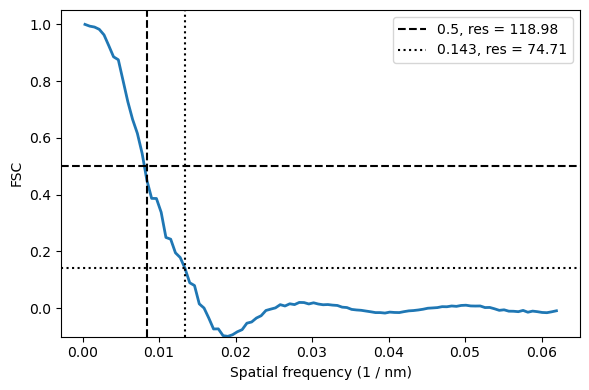

In [ ]:
freqs_z, fsc_dirs_z, res_dirs_z, res_143_dirs_z = fourier_shell_correlation_zdir(
    recon_half1, recon_half2,
    voxel_size=voxel_size_1D,
    n_shells=100,
    plot = True
)

In [ ]:
stop

In [ ]:
## Take the reconstruction of two volumes with half of the angles
voxel_size_1D = 8 # [nm] from meta data

# seperate first half
proj_half1 = rotated[::2]
ang_half1 = ang[::2]
# second half 
proj_half2 = rotated[1::2]
ang_half2  = ang[1::2]

print(len(rotated), len(proj_half1), len(proj_half2))
print(len(ang), len(ang_half1), len(ang_half2))

## Reconstruct 
recon_half1 = reconstruct_and_save(proj_half1, ang_half1, yo_rot, tag="first half", save = False)
recon_half2 = reconstruct_and_save(proj_half2, ang_half2, yo_rot, tag="second half", save = False)

## Run the FSC
freq, fsc, res05, res0143 = fourier_shell_correlation(
    recon_half1,
    recon_half2,
    voxel_size=voxel_size_1D  # 5 nm voxels, for example
)

print(f"Resolution (FSC=0.5): {res05:.1f} nm")
print(f"Resolution (FSC=0.143): {res0143:.1f} nm")

freq, fsc_xy, fsc_z = directional_fsc(
    recon_half1,
    recon_half2,
    voxel_size=voxel_size_1D,
    cone_angle_deg=20
)

res_xy = resolution_at_threshold(freq, fsc_xy, 0.5)
res_z  = resolution_at_threshold(freq, fsc_z, 0.5)

print(f"In-plane resolution: {res_xy:.1f} nm")
print(f"Axial resolution: {res_z:.1f} nm")

In [ ]:
freq, fsc_xy, fsc_z = directional_fsc(
    recon_half1,
    recon_half2,
    voxel_size=voxel_size_1D,
    cone_angle_deg=20
)

res_xy = resolution_at_threshold(freq, fsc_xy, 0.5)
res_z  = resolution_at_threshold(freq, fsc_z, 0.5)

print(f"In-plane resolution: {res_xy:.1f} nm")
print(f"Axial resolution: {res_z:.1f} nm")

In [ ]:
## Take the reconstruction of two volumes with half of the angles
voxel_size_1D = 8 # [nm] from meta data

# seperate first half
proj_half1 = rotated[::2]
ang_half1 = ang[::2]
# second half 
proj_half2 = rotated[1::2]
ang_half2  = ang[1::2]

print(len(rotated), len(proj_half1), len(proj_half2))
print(len(ang), len(ang_half1), len(ang_half2))

## Reconstruct 
recon_half1 = reconstruct_and_save(proj_half1, ang_half1, yo_rot, tag="first half", save = False)
recon_half2 = reconstruct_and_save(proj_half2, ang_half2, yo_rot, tag="second half", save = False)

## Run the FSC
freq, fsc, res05, res0143 = fourier_shell_correlation(
    recon_half1,
    recon_half2,
    voxel_size=voxel_size_1D  # 5 nm voxels, for example
)

print(f"Resolution (FSC=0.5): {res05:.1f} nm")
print(f"Resolution (FSC=0.143): {res0143:.1f} nm")

# freq, fsc_xy, fsc_z = directional_fsc(
#     recon_half1,
#     recon_half2,
#     voxel_size=voxel_size_1D,
#     cone_angle_deg=20
# )

# res_xy = resolution_at_threshold(freq, fsc_xy, 0.5)
# res_z  = resolution_at_threshold(freq, fsc_z, 0.5)

# print(f"In-plane resolution: {res_xy:.1f} nm")
# print(f"Axial resolution: {res_z:.1f} nm")

## Angle dependent

In [ ]:
############################ Every angle ############################

## Take the reconstruction of two volumes with half of the angles
voxel_size_1D = 8 # [nm] from meta data

# seperate first half
proj_half1 = rotated[::2]
ang_half1 = ang[::2]
# second half 
proj_half2 = rotated[1::2]
ang_half2  = ang[1::2]

print(len(recon_shift), len(proj_half1), len(proj_half2))
print(len(ang), len(ang_half1), len(ang_half2))

## Reconstruct 
recon_half1 = reconstruct_and_save(proj_half1, ang_half1, center2, tag="first half", save = False)
recon_half2 = reconstruct_and_save(proj_half2, ang_half2, center2, tag="second half", save = False)

## Run the FSC
freq, fsc, res05, res0143 = fourier_shell_correlation(
    recon_half1,
    recon_half2,
    voxel_size=voxel_size_1D  # 5 nm voxels, for example
)

print(f"Resolution (FSC=0.5): {res05:.1f} nm")
print(f"Resolution (FSC=0.143): {res0143:.1f} nm")

# freq, fsc_xy, fsc_z = directional_fsc(
#     recon_half1,
#     recon_half2,
#     voxel_size=voxel_size_1D,
#     cone_angle_deg=20
# )

# res_xy = resolution_at_threshold(freq, fsc_xy, 0.5)
# res_z  = resolution_at_threshold(freq, fsc_z, 0.5)

# print(f"In-plane resolution: {res_xy:.1f} nm")
# print(f"Axial resolution: {res_z:.1f} nm")

In [ ]:
## Run the FSC
freq, fsc, res05, res0143 = fourier_shell_correlation(
    recon_half1,
    recon_half2,
    voxel_size=voxel_size_1D  # 5 nm voxels, for example
)

print(f"Resolution (FSC=0.5): {res05:.1f} nm")
print(f"Resolution (FSC=0.143): {res0143:.1f} nm")

In [ ]:
F1 = np.fft.fftn(recon_half1)
Nz, Ny, Nx = recon_half1.shape
F1_slice = np.fft.fftshift(F1[257])

kx = np.fft.fftshift(np.fft.fftfreq(Nx, d=8))
ky = np.fft.fftshift(np.fft.fftfreq(Ny, d=8))

extent = [kx[0], kx[-1], ky[0], ky[-1]]

plt.imshow(
    np.log(np.abs(F1_slice)),
    extent=extent,
    origin='lower',
    aspect='auto',
    cmap='viridis'
)

plt.xlabel("$k_x$ (1/nm)")
plt.ylabel("$k_y$ (1/nm)")
plt.title("FT magnitude Volume 1")
plt.colorbar()
plt.show()

In [ ]:
# ## Analyze different angular ranges
# #voxel_size_1D = (4e-6) / (rotated.shape[1]) * (1e9) # [nm] FOV/n

# ############################ Every other ############################
# proj_2 = rotated[::2]
# ang_2  = ang[::2]

# proj_half1_2, ang_half1_2, proj_half2_2, ang_half2_2 = split_proj_for_FSC(proj_2, ang_2)

# ## Reconstruct 
# recon_2 = reconstruct_and_save(proj_2, ang_2, yo_rot, tag="skip_2_rotated", save = True)
# recon_half1_2 = reconstruct_and_save(proj_half1_2, ang_half1_2, yo_rot,tag="first half", save = False)
# recon_half2_2 = reconstruct_and_save(proj_half2_2, ang_half2_2, yo_rot, tag="second half", save = False)

# freq_2, fsc_2, res05_2, res0143_2 = fourier_shell_correlation(
#     recon_half1_2,
#     recon_half2_2,
#     voxel_size=voxel_size_1D  # 5 nm voxels, for example
# )

# # freq_2, fsc_xy_2, fsc_z_2 = directional_fsc(
# #     recon_half1_2,
# #     recon_half2_2,
# #     voxel_size=voxel_size_1D,
# #     cone_angle_deg=20
# # )

# # res_xy_2 = resolution_at_threshold(freq_2, fsc_xy_2, 0.5)
# # res_z_2  = resolution_at_threshold(freq_2, fsc_z_2, 0.5)

# # print(f"In-plane resolution: {res_xy_2*1e9:.1f} nm")
# # print(f"Axial resolution: {res_z_2*1e9:.1f} nm")

In [ ]:
## Analyze different angular ranges
#voxel_size_1D = (4e-6) / (rotated.shape[1]) * (1e9) # [nm] FOV/n

############################ Every other ############################
proj_2 = rotated[::2]
ang_2  = ang[::2]

proj_half1_2, ang_half1_2, proj_half2_2, ang_half2_2 = split_proj_for_FSC(proj_2, ang_2)

## Reconstruct 
recon_2 = reconstruct_and_save(proj_2, ang_2, center2, tag="skip_2_rotated", save = True)
recon_half1_2 = reconstruct_and_save(proj_half1_2, ang_half1_2, center2,tag="first half", save = False)
recon_half2_2 = reconstruct_and_save(proj_half2_2, ang_half2_2, center2, tag="second half", save = False)

freq_2, fsc_2, res05_2, res0143_2 = fourier_shell_correlation(
    recon_half1_2,
    recon_half2_2,
    voxel_size=voxel_size_1D  # 5 nm voxels, for example
)

# freq_2, fsc_xy_2, fsc_z_2 = directional_fsc(
#     recon_half1_2,
#     recon_half2_2,
#     voxel_size=voxel_size_1D,
#     cone_angle_deg=20
# )

# res_xy_2 = resolution_at_threshold(freq_2, fsc_xy_2, 0.5)
# res_z_2  = resolution_at_threshold(freq_2, fsc_z_2, 0.5)

# print(f"In-plane resolution: {res_xy_2*1e9:.1f} nm")
# print(f"Axial resolution: {res_z_2*1e9:.1f} nm")

print(f"Resolution (FSC=0.5): {res05_2:.1f} nm")
print(f"Resolution (FSC=0.143): {res0143_2:.1f} nm")

In [ ]:
############################ Every 3 ############################
proj_3 = rotated[::3]
ang_3  = ang[::3]

proj_half1_3, ang_half1_3, proj_half2_3, ang_half2_3 = split_proj_for_FSC(proj_3, ang_3)

## Reconstruct 
recon_3 = reconstruct_and_save(proj_3, ang_3,center2, tag="skip_3_rotated", save = True)
recon_half1_3 = reconstruct_and_save(proj_half1_3, ang_half1_3,center2, tag="first half", save = False)
recon_half2_3 = reconstruct_and_save(proj_half2_3, ang_half2_3, center2,tag="second half", save = False)

freq_3, fsc_3, res05_3, res0143_3 = fourier_shell_correlation(
    recon_half1_3,
    recon_half2_3,
    voxel_size=voxel_size_1D  # 5 nm voxels, for example
)


# freq_3, fsc_xy_3, fsc_z_3 = directional_fsc(
#     recon_half1_3,
#     recon_half2_3,
#     voxel_size=voxel_size_1D,
#     cone_angle_deg=20
# )

# res_xy_3 = resolution_at_threshold(freq_3, fsc_xy_3, 0.5)
# res_z_3  = resolution_at_threshold(freq_3, fsc_z_3, 0.5)

# print(f"In-plane resolution: {res_xy_3*1e9:.1f} nm")
# print(f"Axial resolution: {res_z_3*1e9:.1f} nm")


In [ ]:
############################ skip5_between_minus15_and_plus15_deg ############################
indices = []
i = 0
n = len(ang_deg)

while i < n:
    if ang_deg[i] < -15:
        indices.append(i)
        i += 1
    elif -15 <= ang_deg[i] <= 15:
        indices.append(i)
        i += 5
    else:  # ang_deg[i] > 15
        indices.append(i)
        i += 1

indices = np.array(indices)

proj_4 = rotated[indices]
ang_4  = ang[indices]

proj_half1_4, ang_half1_4, proj_half2_4, ang_half2_4 = split_proj_for_FSC(proj_4, ang_4)

## Reconstruct 
recon_4 = reconstruct_and_save(proj_4, ang_4, center2,tag="skip5_between_minus15_and_plus15_deg", save = True)
recon_half1_4 = reconstruct_and_save(proj_half1_4, ang_half1_4, center2,tag="first half", save = False)
recon_half2_4 = reconstruct_and_save(proj_half2_4, ang_half2_4, center2,tag="second half", save = False)


freq_4, fsc_4, res05_4, res0143_4 = fourier_shell_correlation(
    recon_half1_4,
    recon_half2_4,
    voxel_size=voxel_size_1D  
)

# freq_4, fsc_xy_4, fsc_z_4 = directional_fsc(
#     recon_half1_4,
#     recon_half2_4,
#     voxel_size=voxel_size_1D,
#     cone_angle_deg=20
# )

# res_xy_4 = resolution_at_threshold(freq_4, fsc_xy_4, 0.5)
# res_z_4  = resolution_at_threshold(freq_4, fsc_z_4, 0.5)

# print(f"In-plane resolution: {res_xy_4*1e9:.1f} nm")
# print(f"Axial resolution: {res_z_4*1e9:.1f} nm")

In [ ]:
############################ skip5_between_minus25_and_plus25_deg ############################
indices = []
i = 0
n = len(ang_deg)

while i < n:
    if ang_deg[i] < -25:
        indices.append(i)
        i += 1
    elif -25 <= ang_deg[i] <= 25:
        indices.append(i)
        i += 5
    else:  # ang_deg[i] > 15
        indices.append(i)
        i += 1

indices = np.array(indices)

proj_5 = rotated[indices]
ang_5  = ang[indices]

proj_half1_5, ang_half1_5, proj_half2_5, ang_half2_5 = split_proj_for_FSC(proj_5, ang_5)

## Reconstruct 
recon_5 = reconstruct_and_save(proj_5, ang_5, center2,tag="skip5_between_minus25_and_plus25_deg", save = True)
recon_half1_5 = reconstruct_and_save(proj_half1_5, ang_half1_5, center2,tag="first half", save = False)
recon_half2_5 = reconstruct_and_save(proj_half2_5, ang_half2_5,center2, tag="second half", save = False)


freq_5, fsc_5, res05_5, res0143_5 = fourier_shell_correlation(
    recon_half1_5,
    recon_half2_5,
    voxel_size=voxel_size_1D  
)


In [ ]:
############################ skip5_between_minus35_and_plus35_deg ############################
indices = []
i = 0
n = len(ang_deg)

while i < n:
    if ang_deg[i] < -35:
        indices.append(i)
        i += 1
    elif -35 <= ang_deg[i] <= 35:
        indices.append(i)
        i += 5
    else:  # ang_deg[i] > 15
        indices.append(i)
        i += 1

indices = np.array(indices)

proj_6 = rotated[indices]
ang_6  = ang[indices]

proj_half1_6, ang_half1_6, proj_half2_6, ang_half2_6 = split_proj_for_FSC(proj_6, ang_6)

## Reconstruct 
recon_6 = reconstruct_and_save(proj_6, ang_6,center2, tag="skip5_between_minus35_and_plus35_deg", save = True)
recon_half1_6 = reconstruct_and_save(proj_half1_6, ang_half1_6, center2,tag="first half", save = False)
recon_half2_6 = reconstruct_and_save(proj_half2_6, ang_half2_6, center2,tag="second half", save = False)


freq_6, fsc_6, res05_6, res0143_6 = fourier_shell_correlation(
    recon_half1_6,
    recon_half2_6,
    voxel_size=voxel_size_1D  
)


In [ ]:
############################ skip5_between_minus45_and_plus45_deg ############################
indices = []
i = 0
n = len(ang_deg)

while i < n:
    if ang_deg[i] < -45:
        indices.append(i)
        i += 1
    elif -45 <= ang_deg[i] <= 45:
        indices.append(i)
        i += 5
    else:  # ang_deg[i] > 15
        indices.append(i)
        i += 1

indices = np.array(indices)

proj_8 = rotated[indices]
ang_8  = ang[indices]

proj_half1_8, ang_half1_8, proj_half2_8, ang_half2_8 = split_proj_for_FSC(proj_8, ang_8)

## Reconstruct 
recon_8 = reconstruct_and_save(proj_8, ang_8,center2, tag="skip5_between_minus45_and_plus45_deg", save = True)
recon_half1_8 = reconstruct_and_save(proj_half1_8, ang_half1_8, center2,tag="first half", save = False)
recon_half2_8 = reconstruct_and_save(proj_half2_8, ang_half2_8, center2,tag="second half", save = False)


freq_8, fsc_8, res05_8, res0143_8 = fourier_shell_correlation(
    recon_half1_8,
    recon_half2_8,
    voxel_size=voxel_size_1D  
)

In [ ]:
############################ skip5_between_minus55_and_plus55_deg ############################
indices = []
i = 0
n = len(ang_deg)

while i < n:
    if ang_deg[i] < -55:
        indices.append(i)
        i += 1
    elif -55 <= ang_deg[i] <= 55:
        indices.append(i)
        i += 5
    else:  # ang_deg[i] > 15
        indices.append(i)
        i += 1

indices = np.array(indices)

proj_7 = rotated[indices]
ang_7  = ang[indices]

proj_half1_7, ang_half1_7, proj_half2_7, ang_half2_7 = split_proj_for_FSC(proj_7, ang_7)

## Reconstruct 
recon_7 = reconstruct_and_save(proj_7, ang_7,center2, tag="skip5_between_minus55_and_plus55_deg", save = True)
recon_half1_7 = reconstruct_and_save(proj_half1_7, ang_half1_7, center2,tag="first half", save = False)
recon_half2_7 = reconstruct_and_save(proj_half2_7, ang_half2_7, center2,tag="second half", save = False)


freq_7, fsc_7, res05_7, res0143_7 = fourier_shell_correlation(
    recon_half1_7,
    recon_half2_7,
    voxel_size=voxel_size_1D  
)

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(freq, fsc, lw=2, label = f'all angles \n FSC 0.5 = {res0143:.2f} nm')
plt.plot(freq_2, fsc_2, lw=2, label = f'every other angle \n FSC 0.143 = {res0143_2:.2f} nm')
plt.plot(freq_3, fsc_3, lw=2, label = f'every three angles \n FSC 0.143 = {res0143_3:.2f} nm')
plt.plot(freq_4, fsc_4, lw=2, label = f'skip 5 angles between +/- 15 \n FSC 0.143 = {res0143_4:.2f} nm')
plt.plot(freq_5, fsc_5, lw=2, label = f'skip 5 angles between +/- 25 \n FSC 0.143 = {res0143_5:.2f} nm')
plt.plot(freq_6, fsc_6, lw=2, label = f'skip 5 angles between +/- 35 \n FSC 0.143 = {res0143_6:.2f} nm')
plt.plot(freq_8, fsc_8, lw=2, label = f'skip 5 angles between +/- 45 \n FSC 0.143 = {res0143_8:.2f} nm')
plt.plot(freq_7, fsc_7, lw=2, label = f'skip 5 angles between +/- 55 \n FSC 0.143 = {res0143_7:.2f} nm')
plt.axhline(0.5, ls='--', color='k', label='0.5')
plt.axhline(0.143, ls=':', color='k', label='0.143')

plt.xlabel('Spatial frequency (1 / nm)')
plt.ylabel('FSC')
plt.ylim(-0.1, 1.05)
# plt.xlim(-0.01, 0.15)
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(6, 4))
res_prog1 = [res0143,res0143_2,res0143_3 ]
res_prog2 = [res0143,res0143_4, res0143_5,res0143_6, res0143_8, res0143_7]

scan =     [1,   4,  5,  6,  2,  8,  3,  7]
ang_used = [94, 74, 58, 46, 47, 38, 32, 26]

ang_prog1 = [94, 47, 32]
ang_prog2 = [ 94, 74, 58, 46, 38, 26]
angles_skipped_prog1 = 94 - np.array(ang_prog1)
angles_skipped_prog2 = 94 - np.array(ang_prog2)

# plt.plot(angles_skipped, res, marker = 'o', label = '0.5')
plt.plot(angles_skipped_prog1, res_prog1, marker = 'o',  label = 'skip every other')
plt.plot(angles_skipped_prog2, res_prog2, marker = 'o',  label = 'skip around 0')

plt.xlabel('angles skipped (from 94 total)')
plt.ylabel('calculated resolution (nm)')
plt.legend(loc = 'upper left')
plt.title('Resoution (0.143) vs total number of angles')


plt.tight_layout()
plt.show()

In [ ]:
stop

In [ ]:
z, y, x = np.array(recon_1.shape) // 2

print(f'x={x}, y={y}, z={z}')

fig, axs = plt.subplots(1, 3, figsize=(12, 4))

axs[0].imshow(recon_3[z, :, :], cmap='viridis')
axs[0].set_title('YX')

axs[1].imshow(recon_3[:, y, :], cmap='viridis')
axs[1].set_title('ZX')

axs[2].imshow(recon_3[:, :, x], cmap='viridis')
axs[2].set_title('ZY')

for ax in axs:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
stop

# Old

In [ ]:
## Rotate the projection 90 degrees so that the axis of rotation is vertical
rotated = rotate(proj,angle=90,axes=(1, 2),reshape=False, order=1)
print(rotated.shape)

fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(proj[45])

ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(rotated[45])

In [ ]:
#### tomography reconstruction on the rotated image

#proj_n = tomopy.prep.alignment.align_joint(proj, ang, save = True, iters=20)
#imsave(os.path.join(PATH,'240707_S1_scatter_aligned.tiff'),proj_n[0])
######## rot_center = tomopy.find_center(proj, ang, init=None, ind=0, tol=0.5) ASSUMES 0 to 180 
# print(rot_center)
#proj = np.roll(proj, 8, axis = 2)



recon = tomopy.recon(rotated, ang, center=yo_rot, algorithm='gridrec', sinogram_order=False) ### 
#recon = tomopy.recon(rotated, ang, algorithm='gridrec', sinogram_order=False)

recon = tomopy.circ_mask(recon, axis=0, ratio=0.90) 


print(recon.shape)

In [ ]:
print(proj.dtype)
print(np.isnan(proj).any(), np.isinf(proj).any())

In [ ]:
plt.matshow(recon[500].clip(min=0));plt.show()

In [ ]:
z, y, x = np.array(recon.shape) // 2

print(f'x={x}, y={y}, z={z}')

fig, axs = plt.subplots(1, 3, figsize=(12, 4))

axs[0].imshow(recon[z, :, :], cmap='viridis')
axs[0].set_title('YX')

axs[1].imshow(recon[:, y, :], cmap='viridis')
axs[1].set_title('ZX')

axs[2].imshow(recon[:, :, x], cmap='viridis')
axs[2].set_title('ZY')

for ax in axs:
    ax.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
i = 256
fig, axs = plt.subplots(1, 3, figsize=(12, 4))

axs[0].imshow(recon[i, :, :], cmap='viridis')
axs[0].set_title('YX')

axs[1].imshow(recon[:, i, :], cmap='viridis')
axs[1].set_title('ZX')

axs[2].imshow(recon[:, :, i], cmap='viridis')
axs[2].set_title('ZY')

for ax in axs:
    ax.axis('off')

plt.tight_layout()
plt.show()

# Compare centering

In [ ]:
#### tomography reconstruction for auto centered image

rot_center = tomopy.find_center(rotated, ang, init=None, ind=0, tol=0.5) ##ASSUMES 0 to 180 
print(f'rot_center={rot_center}')
recon_auto = tomopy.recon(rotated, ang, center=rot_center, algorithm='gridrec', sinogram_order=False) ### 
recon_auto = tomopy.circ_mask(recon_auto, axis=0, ratio=0.90) 

recon_257 = tomopy.recon(rotated, ang, algorithm='gridrec', sinogram_order=False)
recon_257 = tomopy.circ_mask(recon_257, axis=0, ratio=0.90) 


random_px = 280

recon_crazy = tomopy.recon(rotated, ang, center=random_px, algorithm='gridrec', sinogram_order=False)
recon_crazy = tomopy.circ_mask(recon_crazy, axis=0, ratio=0.90) 
print(recon.shape)

In [ ]:
i = 256
fig, axs = plt.subplots(1, 4, figsize=(12, 4))

axs[0].imshow(recon[:, i, :], cmap='viridis')
axs[0].set_title(f'ZX, rotated centroid center = {yo_rot}')

axs[1].imshow(recon_auto[:, i, :], cmap='viridis')
axs[1].set_title(f'ZX, tomopy centering = {rot_center[0]:.2f}')

axs[2].imshow(recon_257[:, i, :], cmap='viridis')
axs[2].set_title(f'ZX, pixel center = {rotated.shape[1]/2}')

axs[3].imshow(recon_crazy[:, i, :], cmap='viridis')
axs[3].set_title(f'ZX, random pixel = {random_px}')

for ax in axs:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
random_px = 240

recon_crazy = tomopy.recon(rotated, ang, center=random_px, algorithm='gridrec', sinogram_order=False)
recon_crazy = tomopy.circ_mask(recon_crazy, axis=0, ratio=0.90) 


x0 = 276

recon_x0 = tomopy.recon(rotated, ang, center=x0, algorithm='gridrec', sinogram_order=False)
recon_x0 = tomopy.circ_mask(recon_x0, axis=0, ratio=0.90) 




In [ ]:
i = 256
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].imshow(recon_crazy[:, i, :], cmap='viridis')
axs[0].set_title(f'ZX, random pixel = {random_px}')

axs[1].imshow(recon_x0[:, i, :], cmap='viridis')
axs[1].set_title(f'ZX, input x centroid = {x0}')


for ax in axs:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
stop

In [ ]:
tifffile.imwrite(f"{Gamma}_recon_vertical.tif", recon.astype(np.float32))

# Fourier Shell Correlation

In [ ]:
def reconstruct_and_save(proj_sub, ang_sub, center, tag, save = True):
    """
    proj_sub : (n, ny, nx)
    ang_sub  : (n,)
    tag      : descriptive string for saving
    """
    print(f"{tag}: using {len(ang_sub)} angles")

    # recon = tomopy.recon(proj_sub, ang_sub, algorithm='gridrec', sinogram_order=False)

    recon = tomopy.recon(proj_sub, ang_sub, center=center, algorithm='gridrec', sinogram_order=False) ### 
    recon = tomopy.circ_mask(recon, axis=0, ratio=0.90) 

    if save:
        tifffile.imwrite(f"{Gamma}_{tag}.tif", recon.astype(np.float32))

    return recon

# Resolution estimates
def resolution_at_threshold(freq, fsc, threshold):
    idx = np.where(fsc < threshold)[0]
    if len(idx) == 0:
        return np.nan
    return 1 / freq[idx[0]]
    
def fourier_shell_correlation(
    vol1,
    vol2,
    voxel_size,
    n_shells=150, ######## good assumption based on image size
    plot=True
):
    """
    Compute Fourier Shell Correlation (FSC) between two 3D volumes.

    Parameters
    ----------
    vol1, vol2 : ndarray
        3D numpy arrays (Nz, Ny, Nx)
    voxel_size : float
        Voxel size in real space (same units as desired resolution)
    n_shells : int
        Number of frequency shells
    plot : bool
        Whether to plot FSC curve

    Returns
    -------
    freq : ndarray
        Spatial frequency (1 / length units)
    fsc : ndarray
        FSC values
    resolution_05 : float
        Resolution at FSC = 0.5 (same units as voxel_size)
    resolution_0143 : float
        Resolution at FSC = 0.143
    """

    assert vol1.shape == vol2.shape, "Volumes must have same shape"

    # Fourier transforms
    F1 = np.fft.fftn(vol1)
    F2 = np.fft.fftn(vol2)

    # Frequency grid
    nz, ny, nx = vol1.shape
    kz = np.fft.fftfreq(nz, d=voxel_size)
    ky = np.fft.fftfreq(ny, d=voxel_size)
    kx = np.fft.fftfreq(nx, d=voxel_size)

    KZ, KY, KX = np.meshgrid(kz, ky, kx, indexing='ij')
    K = np.sqrt(KX**2 + KY**2 + KZ**2)

    # Shell bins
    k_max = K.max()
    shell_edges = np.linspace(0, k_max, n_shells + 1)

    fsc = np.zeros(n_shells)
    freq = np.zeros(n_shells)

    for i in range(n_shells):
        shell_mask = (K >= shell_edges[i]) & (K < shell_edges[i + 1])

        F1_shell = F1[shell_mask]
        F2_shell = F2[shell_mask]

        if F1_shell.size == 0:
            fsc[i] = np.nan
            continue

        num = np.sum(F1_shell * np.conj(F2_shell))
        den = np.sqrt(
            np.sum(np.abs(F1_shell)**2) *
            np.sum(np.abs(F2_shell)**2)
        )

        fsc[i] = np.real(num / den)
        freq[i] = 0.5 * (shell_edges[i] + shell_edges[i + 1])


    resolution_05 = resolution_at_threshold(freq, fsc, 0.5)
    resolution_0143 = resolution_at_threshold(freq, fsc, 0.143)

    if plot:
        plt.figure(figsize=(6, 4))
        plt.plot(freq, fsc, lw=2)
        plt.axhline(0.5, ls='--', color='k', label='0.5')
        plt.axhline(0.143, ls=':', color='k', label='0.143')

        if not np.isnan(resolution_05):
            plt.axvline(1 / resolution_05, ls='--', color='k')
        if not np.isnan(resolution_0143):
            plt.axvline(1 / resolution_0143, ls=':', color='k')

        plt.xlabel('Spatial frequency (1 / nm)')
        plt.ylabel('FSC')
        plt.ylim(-0.1, 1.05)
        plt.legend()
        plt.tight_layout()
        plt.show()

    return freq, fsc, resolution_05, resolution_0143


def split_proj_for_FSC(proj, ang):
    
    proj_half1 = proj[::2]
    ang_half1 = ang[::2]
    
    proj_half2 = proj[1::2]
    ang_half2  = ang[1::2]
    
    print(len(rotated), len(proj_half1), len(proj_half2))
    print(len(ang), len(ang_half1), len(ang_half2))

    return proj_half1, ang_half1, proj_half2, ang_half2

    
def directional_fsc(
    vol1,
    vol2,
    voxel_size,
    n_shells=100,
    cone_angle_deg=20,
    plot=True
):
    """
    Compute directional FSC: in-plane (xy) vs axial (z).

    Parameters
    ----------
    vol1, vol2 : ndarray
        3D reconstructed volumes
    voxel_size : float
        Real-space voxel size
    n_shells : int
        Number of Fourier shells
    cone_angle_deg : float
        Half-angle of directional cone (degrees)
    plot : bool
        Plot FSC curves

    Returns
    -------
    freq : ndarray
        Spatial frequency
    fsc_xy : ndarray
        In-plane FSC
    fsc_z : ndarray
        Axial FSC
    """

    assert vol1.shape == vol2.shape

    F1 = np.fft.fftn(vol1)
    F2 = np.fft.fftn(vol2)

    nz, ny, nx = vol1.shape

    kz = np.fft.fftfreq(nz, d=voxel_size)
    ky = np.fft.fftfreq(ny, d=voxel_size)
    kx = np.fft.fftfreq(nx, d=voxel_size)

    KZ, KY, KX = np.meshgrid(kz, ky, kx, indexing='ij')
    K = np.sqrt(KX**2 + KY**2 + KZ**2)

    # Avoid divide-by-zero
    with np.errstate(divide='ignore', invalid='ignore'):
        cos_theta = np.abs(KZ) / K

    theta = np.arccos(cos_theta) * 180 / np.pi

    alpha = cone_angle_deg

    mask_xy = theta > (90 - alpha)   # in-plane
    mask_z  = theta < alpha          # axial

    k_max = K.max()
    shell_edges = np.linspace(0, k_max, n_shells + 1)

    fsc_xy = np.zeros(n_shells)
    fsc_z  = np.zeros(n_shells)
    freq   = np.zeros(n_shells)

    def compute_fsc(mask):
        fsc = np.zeros(n_shells)
        for i in range(n_shells):
            shell = (K >= shell_edges[i]) & (K < shell_edges[i+1]) & mask
            F1s = F1[shell]
            F2s = F2[shell]

            if F1s.size < 10:
                fsc[i] = np.nan
                continue

            num = np.sum(F1s * np.conj(F2s))
            den = np.sqrt(
                np.sum(np.abs(F1s)**2) *
                np.sum(np.abs(F2s)**2)
            )
            fsc[i] = np.real(num / den)
        return fsc

    fsc_xy = compute_fsc(mask_xy)
    fsc_z  = compute_fsc(mask_z)

    for i in range(n_shells):
        freq[i] = 0.5 * (shell_edges[i] + shell_edges[i+1])

    resolution_05 = resolution_at_threshold(freq, fsc, 0.5)
    resolution_0143 = resolution_at_threshold(freq, fsc, 0.143)

    if plot:
        plt.figure(figsize=(6, 4))
        plt.plot(freq, fsc_xy, label='In-plane (xy)', lw=2)
        plt.plot(freq, fsc_z, label='Axial (z)', lw=2)
        
        plt.axhline(0.5, ls='--', color='k', label='0.5')
        plt.axhline(0.143, ls=':', color='k', label='0.143')

        if not np.isnan(resolution_05):
            plt.axvline(1 / resolution_05, ls='--', color='k')
        if not np.isnan(resolution_0143):
            plt.axvline(1 / resolution_0143, ls=':', color='k')

        plt.xlabel('Spatial frequency (1 / nm)')
        plt.ylabel('FSC')
        plt.ylim(-0.1, 1.05)
        plt.legend()
        plt.tight_layout()
        plt.show()

    return freq, fsc_xy, fsc_z

In [ ]:
rotated.shape[0]

In [ ]:
## Take the reconstruction of two volumes with half of the angles
voxel_size_1D = (4e-6) / (rotated.shape[1]) * (1e9) # [nm] FOV/n
print(voxel_size_1D)
proj_half1 = rotated[::2]
ang_half1 = ang[::2]

proj_half2 = rotated[1::2]
ang_half2  = ang[1::2]

print(len(rotated), len(proj_half1), len(proj_half2))
print(len(ang), len(ang_half1), len(ang_half2))

## Reconstruct 
recon_half1 = reconstruct_and_save(proj_half1, ang_half1, yo_rot, tag="first half", save = False)
recon_half2 = reconstruct_and_save(proj_half2, ang_half2, yo_rot, tag="second half", save = False)

## Run the FSC
freq, fsc, res05, res0143 = fourier_shell_correlation(
    recon_half1,
    recon_half2,
    voxel_size=voxel_size_1D  # 5 nm voxels, for example
)

print(f"Resolution (FSC=0.5): {res05:.1f} nm")
print(f"Resolution (FSC=0.143): {res0143:.1f} nm")

freq, fsc_xy, fsc_z = directional_fsc(
    recon_half1,
    recon_half2,
    voxel_size=voxel_size_1D,
    cone_angle_deg=20
)

res_xy = resolution_at_threshold(freq, fsc_xy, 0.5)
res_z  = resolution_at_threshold(freq, fsc_z, 0.5)

print(f"In-plane resolution: {res_xy:.1f} nm")
print(f"Axial resolution: {res_z:.1f} nm")

In [ ]:


freq, fsc_xy, fsc_z = directional_fsc(
    recon_half1,
    recon_half2,
    voxel_size=voxel_size_1D,
    cone_angle_deg=20
)




In [ ]:
res_xy = resolution_at_threshold(freq, fsc_xy, 0.5)
res_z  = resolution_at_threshold(freq, fsc_z, 0.5)

print(f"In-plane resolution: {res_xy:.1f} nm")
print(f"Axial resolution: {res_z:.1f} nm")

In [ ]:
stop

In [ ]:
Gamma

In [ ]:
import tifffile
tifffile.imwrite(f"{Gamma}_recon_vertical.tif", recon.astype(np.float32))


In [ ]:
tomopy.__file__

In [ ]:
print(np.__file__)
np.__version__

In [ ]:
import matplotlib
matplotlib.__file__

# look at different angles

In [ ]:
Gamma

In [ ]:
import tifffile

def analyze_and_save(proj_sub, ang_sub, center, tag):
    """
    proj_sub : (n, ny, nx)
    ang_sub  : (n,)
    tag      : descriptive string for saving
    """
    print(f"{tag}: using {len(ang_sub)} angles")

    # recon = tomopy.recon(proj_sub, ang_sub, algorithm='gridrec', sinogram_order=False)

    recon = tomopy.recon(proj_sub, ang_sub, center=center, algorithm='gridrec', sinogram_order=False) ### 
    recon = tomopy.circ_mask(recon, axis=0, ratio=0.90) 

    tifffile.imwrite(f"{Gamma}_{tag}.tif", recon.astype(np.float32))

    return recon


In [ ]:
## Analyze different angular ranges
voxel_size_1D = (4e-6) / (rotated.shape[1]) * (1e9) # [nm] FOV/n

############################ Every other ############################
proj_2 = rotated[::2]
ang_2  = ang[::2]

proj_half1_2, ang_half1_2, proj_half2_2, ang_half2_2 = split_proj_for_FSC(proj_2, ang_2)

## Reconstruct 
recon_2 = reconstruct_and_save(proj_2, ang_2, yo_rot, tag="skip_2_rotated", save = True)
recon_half1_2 = reconstruct_and_save(proj_half1_2, ang_half1_2, yo_rot,tag="first half", save = False)
recon_half2_2 = reconstruct_and_save(proj_half2_2, ang_half2_2, yo_rot, tag="second half", save = False)

freq_2, fsc_2, res05_2, res0143_2 = fourier_shell_correlation(
    recon_half1_2,
    recon_half2_2,
    voxel_size=voxel_size_1D  # 5 nm voxels, for example
)

# freq_2, fsc_xy_2, fsc_z_2 = directional_fsc(
#     recon_half1_2,
#     recon_half2_2,
#     voxel_size=voxel_size_1D,
#     cone_angle_deg=20
# )

# res_xy_2 = resolution_at_threshold(freq_2, fsc_xy_2, 0.5)
# res_z_2  = resolution_at_threshold(freq_2, fsc_z_2, 0.5)

# print(f"In-plane resolution: {res_xy_2*1e9:.1f} nm")
# print(f"Axial resolution: {res_z_2*1e9:.1f} nm")



In [ ]:
############################ Every 3 ############################
proj_3 = rotated[::3]
ang_3  = ang[::3]

proj_half1_3, ang_half1_3, proj_half2_3, ang_half2_3 = split_proj_for_FSC(proj_3, ang_3)

## Reconstruct 
recon_3 = reconstruct_and_save(proj_3, ang_3,yo_rot, tag="skip_3_rotated", save = True)
recon_half1_3 = reconstruct_and_save(proj_half1_3, ang_half1_3,yo_rot, tag="first half", save = False)
recon_half2_3 = reconstruct_and_save(proj_half2_3, ang_half2_3, yo_rot,tag="second half", save = False)

freq_3, fsc_3, res05_3, res0143_3 = fourier_shell_correlation(
    recon_half1_3,
    recon_half2_3,
    voxel_size=voxel_size_1D  # 5 nm voxels, for example
)


# freq_3, fsc_xy_3, fsc_z_3 = directional_fsc(
#     recon_half1_3,
#     recon_half2_3,
#     voxel_size=voxel_size_1D,
#     cone_angle_deg=20
# )

# res_xy_3 = resolution_at_threshold(freq_3, fsc_xy_3, 0.5)
# res_z_3  = resolution_at_threshold(freq_3, fsc_z_3, 0.5)

# print(f"In-plane resolution: {res_xy_3*1e9:.1f} nm")
# print(f"Axial resolution: {res_z_3*1e9:.1f} nm")



In [ ]:
############################ skip5_between_minus15_and_plus15_deg ############################
indices = []
i = 0
n = len(ang_deg)

while i < n:
    if ang_deg[i] < -15:
        indices.append(i)
        i += 1
    elif -15 <= ang_deg[i] <= 15:
        indices.append(i)
        i += 5
    else:  # ang_deg[i] > 15
        indices.append(i)
        i += 1

indices = np.array(indices)

proj_4 = rotated[indices]
ang_4  = ang[indices]

proj_half1_4, ang_half1_4, proj_half2_4, ang_half2_4 = split_proj_for_FSC(proj_4, ang_4)

## Reconstruct 
recon_4 = reconstruct_and_save(proj_4, ang_4, yo_rot,tag="skip5_between_minus15_and_plus15_deg", save = True)
recon_half1_4 = reconstruct_and_save(proj_half1_4, ang_half1_4, yo_rot,tag="first half", save = False)
recon_half2_4 = reconstruct_and_save(proj_half2_4, ang_half2_4, yo_rot,tag="second half", save = False)


freq_4, fsc_4, res05_4, res0143_4 = fourier_shell_correlation(
    recon_half1_4,
    recon_half2_4,
    voxel_size=voxel_size_1D  
)

# freq_4, fsc_xy_4, fsc_z_4 = directional_fsc(
#     recon_half1_4,
#     recon_half2_4,
#     voxel_size=voxel_size_1D,
#     cone_angle_deg=20
# )

# res_xy_4 = resolution_at_threshold(freq_4, fsc_xy_4, 0.5)
# res_z_4  = resolution_at_threshold(freq_4, fsc_z_4, 0.5)

# print(f"In-plane resolution: {res_xy_4*1e9:.1f} nm")
# print(f"Axial resolution: {res_z_4*1e9:.1f} nm")

In [ ]:
############################ skip5_between_minus25_and_plus25_deg ############################
indices = []
i = 0
n = len(ang_deg)

while i < n:
    if ang_deg[i] < -25:
        indices.append(i)
        i += 1
    elif -25 <= ang_deg[i] <= 25:
        indices.append(i)
        i += 5
    else:  # ang_deg[i] > 15
        indices.append(i)
        i += 1

indices = np.array(indices)

proj_5 = rotated[indices]
ang_5  = ang[indices]

proj_half1_5, ang_half1_5, proj_half2_5, ang_half2_5 = split_proj_for_FSC(proj_5, ang_5)

## Reconstruct 
recon_5 = reconstruct_and_save(proj_5, ang_5, yo_rot,tag="skip5_between_minus25_and_plus25_deg", save = True)
recon_half1_5 = reconstruct_and_save(proj_half1_5, ang_half1_5, yo_rot,tag="first half", save = False)
recon_half2_5 = reconstruct_and_save(proj_half2_5, ang_half2_5,yo_rot, tag="second half", save = False)


freq_5, fsc_5, res05_5, res0143_5 = fourier_shell_correlation(
    recon_half1_5,
    recon_half2_5,
    voxel_size=voxel_size_1D  
)


In [ ]:
############################ skip5_between_minus35_and_plus35_deg ############################
indices = []
i = 0
n = len(ang_deg)

while i < n:
    if ang_deg[i] < -35:
        indices.append(i)
        i += 1
    elif -35 <= ang_deg[i] <= 35:
        indices.append(i)
        i += 5
    else:  # ang_deg[i] > 15
        indices.append(i)
        i += 1

indices = np.array(indices)

proj_6 = rotated[indices]
ang_6  = ang[indices]

proj_half1_6, ang_half1_6, proj_half2_6, ang_half2_6 = split_proj_for_FSC(proj_6, ang_6)

## Reconstruct 
recon_6 = reconstruct_and_save(proj_6, ang_6,yo_rot, tag="skip5_between_minus35_and_plus35_deg", save = True)
recon_half1_6 = reconstruct_and_save(proj_half1_6, ang_half1_6, yo_rot,tag="first half", save = False)
recon_half2_6 = reconstruct_and_save(proj_half2_6, ang_half2_6, yo_rot,tag="second half", save = False)


freq_6, fsc_6, res05_6, res0143_6 = fourier_shell_correlation(
    recon_half1_6,
    recon_half2_6,
    voxel_size=voxel_size_1D  
)


In [ ]:
############################ skip5_between_minus45_and_plus45_deg ############################
indices = []
i = 0
n = len(ang_deg)

while i < n:
    if ang_deg[i] < -45:
        indices.append(i)
        i += 1
    elif -45 <= ang_deg[i] <= 45:
        indices.append(i)
        i += 5
    else:  # ang_deg[i] > 15
        indices.append(i)
        i += 1

indices = np.array(indices)

proj_8 = rotated[indices]
ang_8  = ang[indices]

proj_half1_8, ang_half1_8, proj_half2_8, ang_half2_8 = split_proj_for_FSC(proj_8, ang_8)

## Reconstruct 
recon_8 = reconstruct_and_save(proj_8, ang_8,yo_rot, tag="skip5_between_minus45_and_plus45_deg", save = True)
recon_half1_8 = reconstruct_and_save(proj_half1_8, ang_half1_8, yo_rot,tag="first half", save = False)
recon_half2_8 = reconstruct_and_save(proj_half2_8, ang_half2_8, yo_rot,tag="second half", save = False)


freq_8, fsc_8, res05_8, res0143_8 = fourier_shell_correlation(
    recon_half1_8,
    recon_half2_8,
    voxel_size=voxel_size_1D  
)

In [ ]:
############################ skip5_between_minus55_and_plus55_deg ############################
indices = []
i = 0
n = len(ang_deg)

while i < n:
    if ang_deg[i] < -55:
        indices.append(i)
        i += 1
    elif -55 <= ang_deg[i] <= 55:
        indices.append(i)
        i += 5
    else:  # ang_deg[i] > 15
        indices.append(i)
        i += 1

indices = np.array(indices)

proj_7 = rotated[indices]
ang_7  = ang[indices]

proj_half1_7, ang_half1_7, proj_half2_7, ang_half2_7 = split_proj_for_FSC(proj_7, ang_7)

## Reconstruct 
recon_7 = reconstruct_and_save(proj_7, ang_7,yo_rot, tag="skip5_between_minus55_and_plus55_deg", save = True)
recon_half1_7 = reconstruct_and_save(proj_half1_7, ang_half1_7, yo_rot,tag="first half", save = False)
recon_half2_7 = reconstruct_and_save(proj_half2_7, ang_half2_7, yo_rot,tag="second half", save = False)


freq_7, fsc_7, res05_7, res0143_7 = fourier_shell_correlation(
    recon_half1_7,
    recon_half2_7,
    voxel_size=voxel_size_1D  
)

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(freq, fsc, lw=2, label = f'all angles \n FSC 0.5 = {res05:.2f} nm')
plt.plot(freq_2, fsc_2, lw=2, label = f'every other angle \n FSC 0.5 = {res05_2:.2f} nm')
plt.plot(freq_3, fsc_3, lw=2, label = f'every three angles \n FSC 0.5 = {res05_3:.2f} nm')
plt.plot(freq_4, fsc_4, lw=2, label = f'skip 5 angles between +/- 15 \n FSC 0.5 = {res05_4:.2f} nm')
plt.plot(freq_5, fsc_5, lw=2, label = f'skip 5 angles between +/- 25 \n FSC 0.5 = {res05_5:.2f} nm')
plt.plot(freq_6, fsc_6, lw=2, label = f'skip 5 angles between +/- 35 \n FSC 0.5 = {res05_6:.2f} nm')
plt.plot(freq_8, fsc_8, lw=2, label = f'skip 5 angles between +/- 45 \n FSC 0.5 = {res05_8:.2f} nm')
plt.plot(freq_7, fsc_7, lw=2, label = f'skip 5 angles between +/- 55 \n FSC 0.5 = {res05_7:.2f} nm')
plt.axhline(0.5, ls='--', color='k', label='0.5')
plt.axhline(0.143, ls=':', color='k', label='0.143')

plt.xlabel('Spatial frequency (1 / nm)')
plt.ylabel('FSC')
plt.ylim(-0.1, 1.05)
# plt.xlim(-0.01, 0.15)
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(6, 4))
res = [res05,res05_4, res05_5,res05_6, res05_2, res05_8, res05_3, res05_7]
res_143 = [res0143,res0143_4, res0143_5,res0143_6, res0143_2, res0143_8, res0143_3, res0143_7]
scan =     [1,   4,  5,  6,  2,  8,  3,  7]
ang_used = [94, 74, 58, 46, 47, 38, 32, 26]
angles_skipped = 94 - np.array(ang_used)

plt.plot(angles_skipped, res, marker = 'o', label = '0.5')
plt.plot(angles_skipped, res_143, marker = 'o', label = '0.143')

plt.xlabel('angles skipped (from 94 total)')
plt.ylabel('calculated resolution (nm)')
plt.legend(loc = 'upper left')


plt.tight_layout()
plt.show()

In [ ]:
z, y, x = np.array(recon_1.shape) // 2

print(f'x={x}, y={y}, z={z}')

fig, axs = plt.subplots(1, 3, figsize=(12, 4))

axs[0].imshow(recon_3[z, :, :], cmap='viridis')
axs[0].set_title('YX')

axs[1].imshow(recon_3[:, y, :], cmap='viridis')
axs[1].set_title('ZX')

axs[2].imshow(recon_3[:, :, x], cmap='viridis')
axs[2].set_title('ZY')

for ax in axs:
    ax.axis('off')

plt.tight_layout()
plt.show()